In [1]:
import read_utils
import plot_utils
import train_utils
import artificializer
from models import glm_sep as glm
from models import hgm_sep as hgm

import os
import math
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd

from sklearn.decomposition import PCA
from sklearn.cross_decomposition import CCA

from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.model_selection import TimeSeriesSplit, StratifiedKFold

import jax
import jax.numpy as jnp
import optax

In [2]:
__gl_params = None

def train_numerical_model(model, splits, X, Y, X_man=None, hyperparams=None):
	is_hgm = model.get_type()

	seed = jax.random.PRNGKey(0)

	n_neurons = Y.shape[1]
	n_behaviors_ll = X.shape[1]
	if is_hgm: n_dimensions = X_man.shape[1]

	# Hyperparamters ============
	if hyperparams is None:
		hyperparams = {
			'max_epochs': 200,
			'min_epochs': 200,  # no early stopping
			'max_patience': 0,
			'learning_rate': 1E-3,
			'reg_l1': 0.01,
			'reg_l2': 0.0,
		}

	max_epochs = hyperparams['max_epochs']
	min_epochs = hyperparams['min_epochs']
	max_patience = hyperparams['max_patience']

	optimizer = optax.adam(hyperparams['learning_rate'])

	reg_lambdas = hyperparams['reg_l1'], hyperparams['reg_l2']
	# ===========================

	# training loop =======================================
	neuron_scores_per_split = list()
	losses_per_split = list()
	losses_tr_per_split = list()
	__grads_per_split = list()
	for train, test in splits:
		# splitting and initializing ===============================================================
		X_train, X_test = X[train], X[test]
		if is_hgm: X_man_train, X_man_test = X_man[train], X_man[test]
		Y_train, Y_test = Y[train], Y[test]

		if is_hgm:
			params = model.init_params(seed, (n_behaviors_ll, n_neurons), (n_dimensions, n_neurons))
		else:
			params = model.init_params(seed, (n_behaviors_ll, n_neurons))
		opt_state = optimizer.init(params)
		# ==========================================================================================

		if is_hgm:
			losses = [model.loss_fn(params, X_test, X_man_test, Y_test, reg_lambdas).item()]
			losses_tr = [model.loss_fn(params, X_train, X_man_train, Y_train, reg_lambdas).item()]
		else:
			losses = [model.loss_fn(params, X_test, Y_test, reg_lambdas).item()]
			losses_tr = [model.loss_fn(params, X_train, Y_train, reg_lambdas).item()]
		__grads = list()

		best_params = params
		best_loss = 1.1
		best_loss_tr = 1.1

		patience = 0
		for epoch in range(max_epochs):
			if is_hgm:
				params, opt_state, __grad = model.update(optimizer.update, opt_state, params, X_train, X_man_train, Y_train, reg_lambdas)
				loss = model.loss_fn(params, X_test, X_man_test, Y_test, reg_lambdas).item()
				loss_tr = model.loss_fn(params, X_train, X_man_train, Y_train, reg_lambdas).item()
			else:
				params, opt_state, __grad = model.update(optimizer.update, opt_state, params, X_train, Y_train, reg_lambdas)
				loss = model.loss_fn(params, X_test, Y_test, reg_lambdas).item()
				loss_tr = model.loss_fn(params, X_train, Y_train, reg_lambdas).item()

			__grads.append(__grad)

			# early stopping ================
			if epoch > min_epochs:
				if loss < best_loss:
					losses.append(loss)
					losses_tr.append(loss_tr)
					best_loss = loss
					best_loss_tr = loss_tr
					best_params = params
					patience = 0
				else:
					patience += 1
					if patience > max_patience:
						losses_padding = [best_loss for _ in range(max_epochs - len(losses) + 1)]
						losses = losses + losses_padding
						losses_tr_padding = [best_loss_tr for _ in range(max_epochs - len(losses_tr) + 1)]
						losses_tr = losses_tr + losses_tr_padding
						break
					losses.append(loss)
					losses_tr.append(loss_tr)
			# ===============================
			else:
				best_params = params
				losses.append(loss)
				losses_tr.append(loss_tr)
		losses_per_split.append(losses)
		losses_tr_per_split.append(losses_tr)

		__grads_per_split.append(__grads)

		# predicting and scoring ========================================================================
		if is_hgm:
			Y_pred = model.predict(X_test, X_man_test, best_params['W1'], best_params['W2'])
		else:
			Y_pred = model.predict(X_test, best_params['W'])

		score_per_neuron = [r2_score(trace, trace_pred) for trace, trace_pred in zip(Y_test.T, Y_pred.T)]
		neuron_scores_per_split.append(score_per_neuron)

		global __gl_params
		__gl_params = best_params
		# ===============================================================================================

	# =====================================================

	return np.array(neuron_scores_per_split), np.array(losses_per_split), np.array(losses_tr_per_split), __grads_per_split

__gl_params_alr = None
def fit_analytical_model(splits, X, Y):
	neuron_score_per_split = list()
	loss_per_split = list()
	loss_tr_per_split = list()
	for train, test in splits:
		X_train, X_test = X[train], X[test]
		Y_train, Y_test = Y[train], Y[test]

		model = LinearRegression(fit_intercept=False)
		model.fit(X_train, Y_train)
		global __gl_params_alr
		__gl_params_alr = model.coef_

		Y_pred = model.predict(X_test)
		loss = jnp.mean((Y_pred - Y_test) ** 2)  # mean. consider alternatives
		loss_tr = jnp.mean((model.predict(X_train) - Y_train) ** 2)
		score_per_neuron = [r2_score(trace, trace_pred) for trace, trace_pred in zip(Y_test.T, Y_pred.T)]

		neuron_score_per_split.append(np.array(score_per_neuron))
		loss_per_split.append(loss)
		loss_tr_per_split.append(loss_tr)

	return np.array(neuron_score_per_split), np.array(loss_per_split), np.array(loss_tr_per_split)

# read & preprocess (GCamp & GFP)

In [3]:
path = f'{os.getcwd()}/../data/{os.path.basename(os.getcwd())}/exported_data_/'
filenames, continuous_behaviors, discrete_states, eigenworms, kymographs, traces = read_utils.get_data(path)

path_gfp = f'{os.getcwd()}/../data/{os.path.basename(os.getcwd())}/exported_data_gfp/'
filenames_gfp, continuous_behaviors_gfp, discrete_states_gfp, eigenworms_gfp, kymographs_gfp, traces_gfp = read_utils.get_data(path_gfp)

for i in range(len(filenames)):
	mask = eigenworms[i].notna().all(axis=1)
	#continuous_behaviors[i] = continuous_behaviors[i][mask]
	discrete_states[i] = discrete_states[i][mask]
	eigenworms[i] = eigenworms[i][mask]
	traces[i] = traces[i][mask]

	#kymographs[i] = kymographs[i][mask]
	#filenames[i] = filenames[i][mask]

for i in range(len(filenames_gfp)):
	mask = eigenworms_gfp[i].notna().all(axis=1)
	#continuous_behaviors_gfp[i] = continuous_behaviors_gfp[i][mask]
	discrete_states_gfp[i] = discrete_states_gfp[i][mask]
	eigenworms_gfp[i] = eigenworms_gfp[i][mask]
	traces_gfp[i] = traces_gfp[i][mask]

	#kymographs_gfp[i] = kymographs_gfp[i][mask]
	#filenames_gfp[i] = filenames_gfp[i][mask]

# ARTIFICIAL DATA

In [4]:
filenames_art = list()
discrete_states_art = discrete_states_gfp.copy()
eigenworms_art = eigenworms_gfp.copy()
traces_art = list()
traces_residual_art = list()
modes_manifold_art = list()
for i in range(len(filenames_gfp)):
	art_filename, art_trace, art_trace_residual, mode_manifold_art, art_params = artificializer.artificialize(filenames_gfp[i], traces_gfp[i].columns, eigenworms_gfp[i], discrete_states_gfp[i])
	filenames_art.append(art_filename)
	traces_art.append(art_trace)
	traces_residual_art.append(art_trace_residual)
	modes_manifold_art.append(mode_manifold_art)

In [5]:
# alr art

alr_models_scores_art = list()
alr_models_losses_art = list()
alr_models_losses_tr_art = list()
# alr_models_params_art = list()
__alr_models_grads_art = list()

for i in range(len(filenames_art)):
	print(f'{i+1}/{len(filenames_art)}: {filenames_art[i]} ', end='')

	splits = list(StratifiedKFold(n_splits=5).split(np.zeros(eigenworms_art[i].values.shape[0]), discrete_states_art[i]['REV'].values))

	neuron_score_per_split, loss_per_split, loss_tr_per_split = fit_analytical_model(splits, eigenworms_art[i].values, traces_residual_art[i].values)

	alr_models_scores_art.append(neuron_score_per_split)
	alr_models_losses_art.append(loss_per_split)
	alr_models_losses_tr_art.append(loss_tr_per_split)

1/8: ZIMMERMANN_artificial_worm3-2022-12-10_no_image_data 2/8: ZIMMERMANN_artificial_worm1-2022-12-10_no_image_data 3/8: ZIMMERMANN_artificial_worm2-2022-12-10_no_image_data 4/8: ZIMMERMANN_artificial_worm6-2022-12-10_no_image_data 5/8: ZIMMERMANN_artificial_worm8-2022-12-10_no_image_data 6/8: ZIMMERMANN_artificial_worm4-2022-12-10_no_image_data 7/8: ZIMMERMANN_artificial_worm7-2022-12-10_no_image_data 8/8: ZIMMERMANN_artificial_worm5-2022-12-10_no_image_data 

In [6]:
# glm art

glm_models_scores_art = list()
glm_models_losses_art = list()
glm_models_losses_tr_art = list()
# glm_models_params_art = list()
__glm_models_grads_art = list()

for i in range(len(filenames_art)):
	print(f'{i + 1}/{len(filenames_art)}: {filenames_art[i]}  ', end='')

	splits = list(StratifiedKFold(n_splits=5).split(np.zeros(eigenworms_art[i].values.shape[0]), discrete_states_art[i]['REV'].values))

	neuron_scores_per_split, losses_per_split, losses_tr_per_split, __grads_per_split = train_numerical_model(glm, splits,
																											  jnp.array(eigenworms_art[i].values),
																											  jnp.array(traces_residual_art[i].values),
																											  None)

	glm_models_scores_art.append(neuron_scores_per_split)
	glm_models_losses_art.append(losses_per_split)
	glm_models_losses_tr_art.append(losses_tr_per_split)
	__glm_models_grads_art.append(__grads_per_split)

1/8: ZIMMERMANN_artificial_worm3-2022-12-10_no_image_data  2/8: ZIMMERMANN_artificial_worm1-2022-12-10_no_image_data  3/8: ZIMMERMANN_artificial_worm2-2022-12-10_no_image_data  4/8: ZIMMERMANN_artificial_worm6-2022-12-10_no_image_data  5/8: ZIMMERMANN_artificial_worm8-2022-12-10_no_image_data  6/8: ZIMMERMANN_artificial_worm4-2022-12-10_no_image_data  7/8: ZIMMERMANN_artificial_worm7-2022-12-10_no_image_data  8/8: ZIMMERMANN_artificial_worm5-2022-12-10_no_image_data  

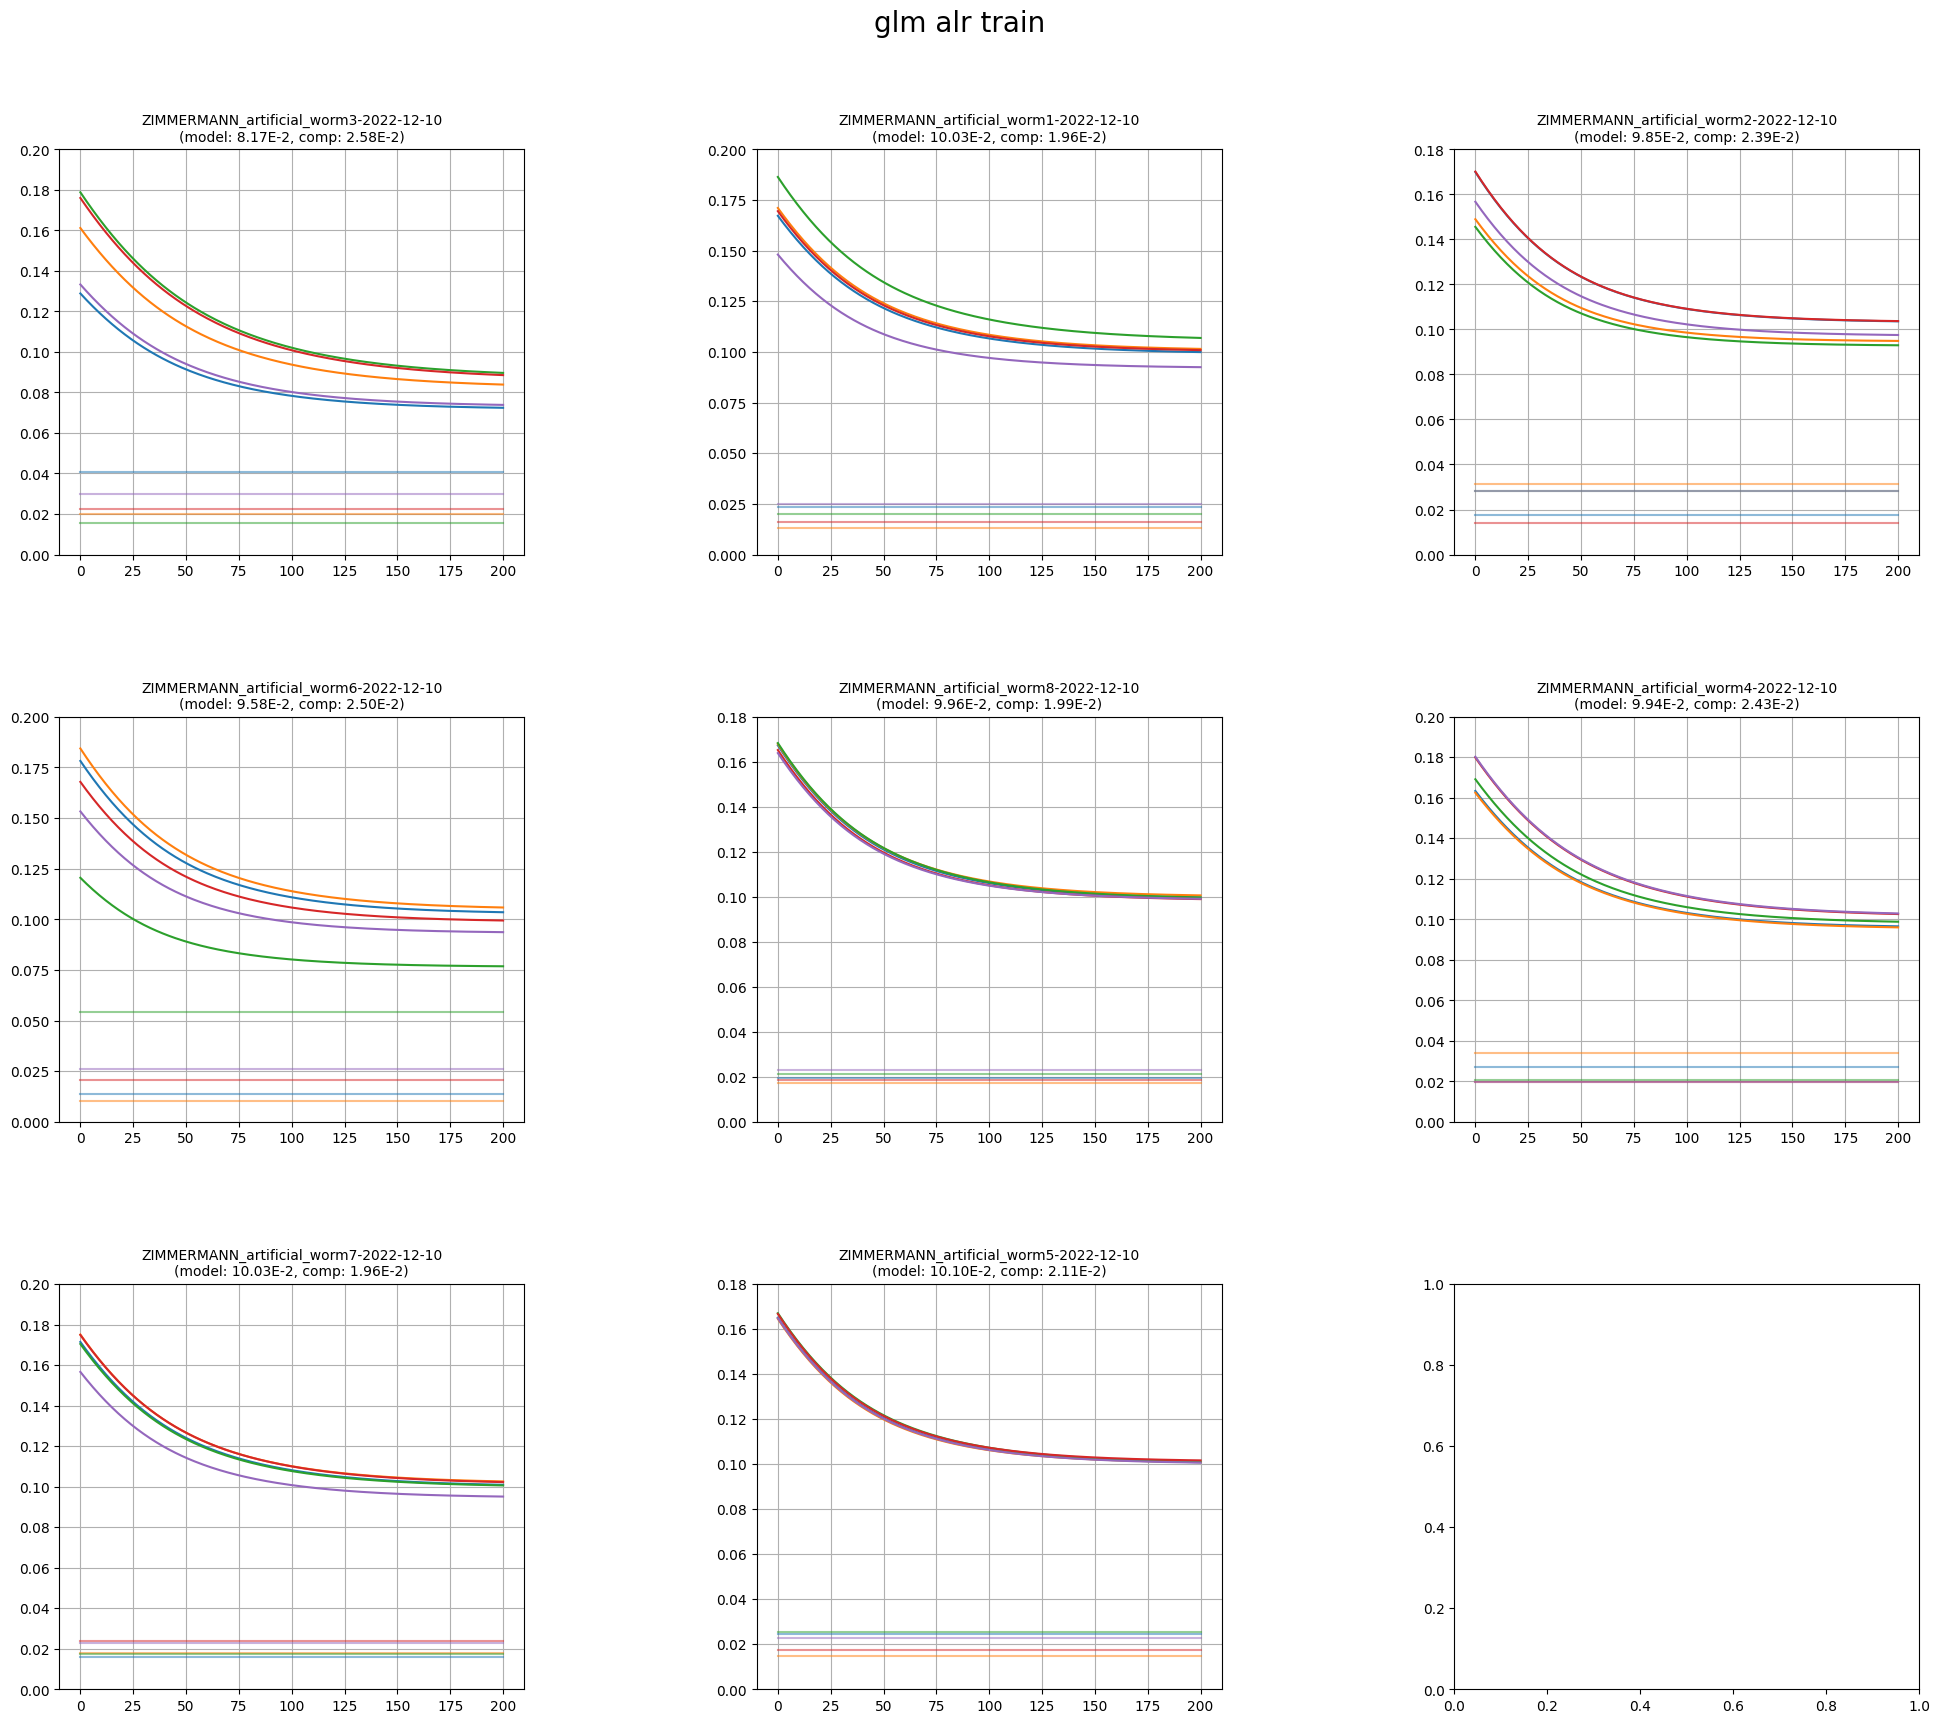

In [7]:
plot_utils.plot_losses(filenames_art, glm_models_losses_tr_art, [loss[:, None] * np.ones((1, glm_models_losses_tr_art[0].shape[1])) for loss in alr_models_losses_art], 'glm alr train')

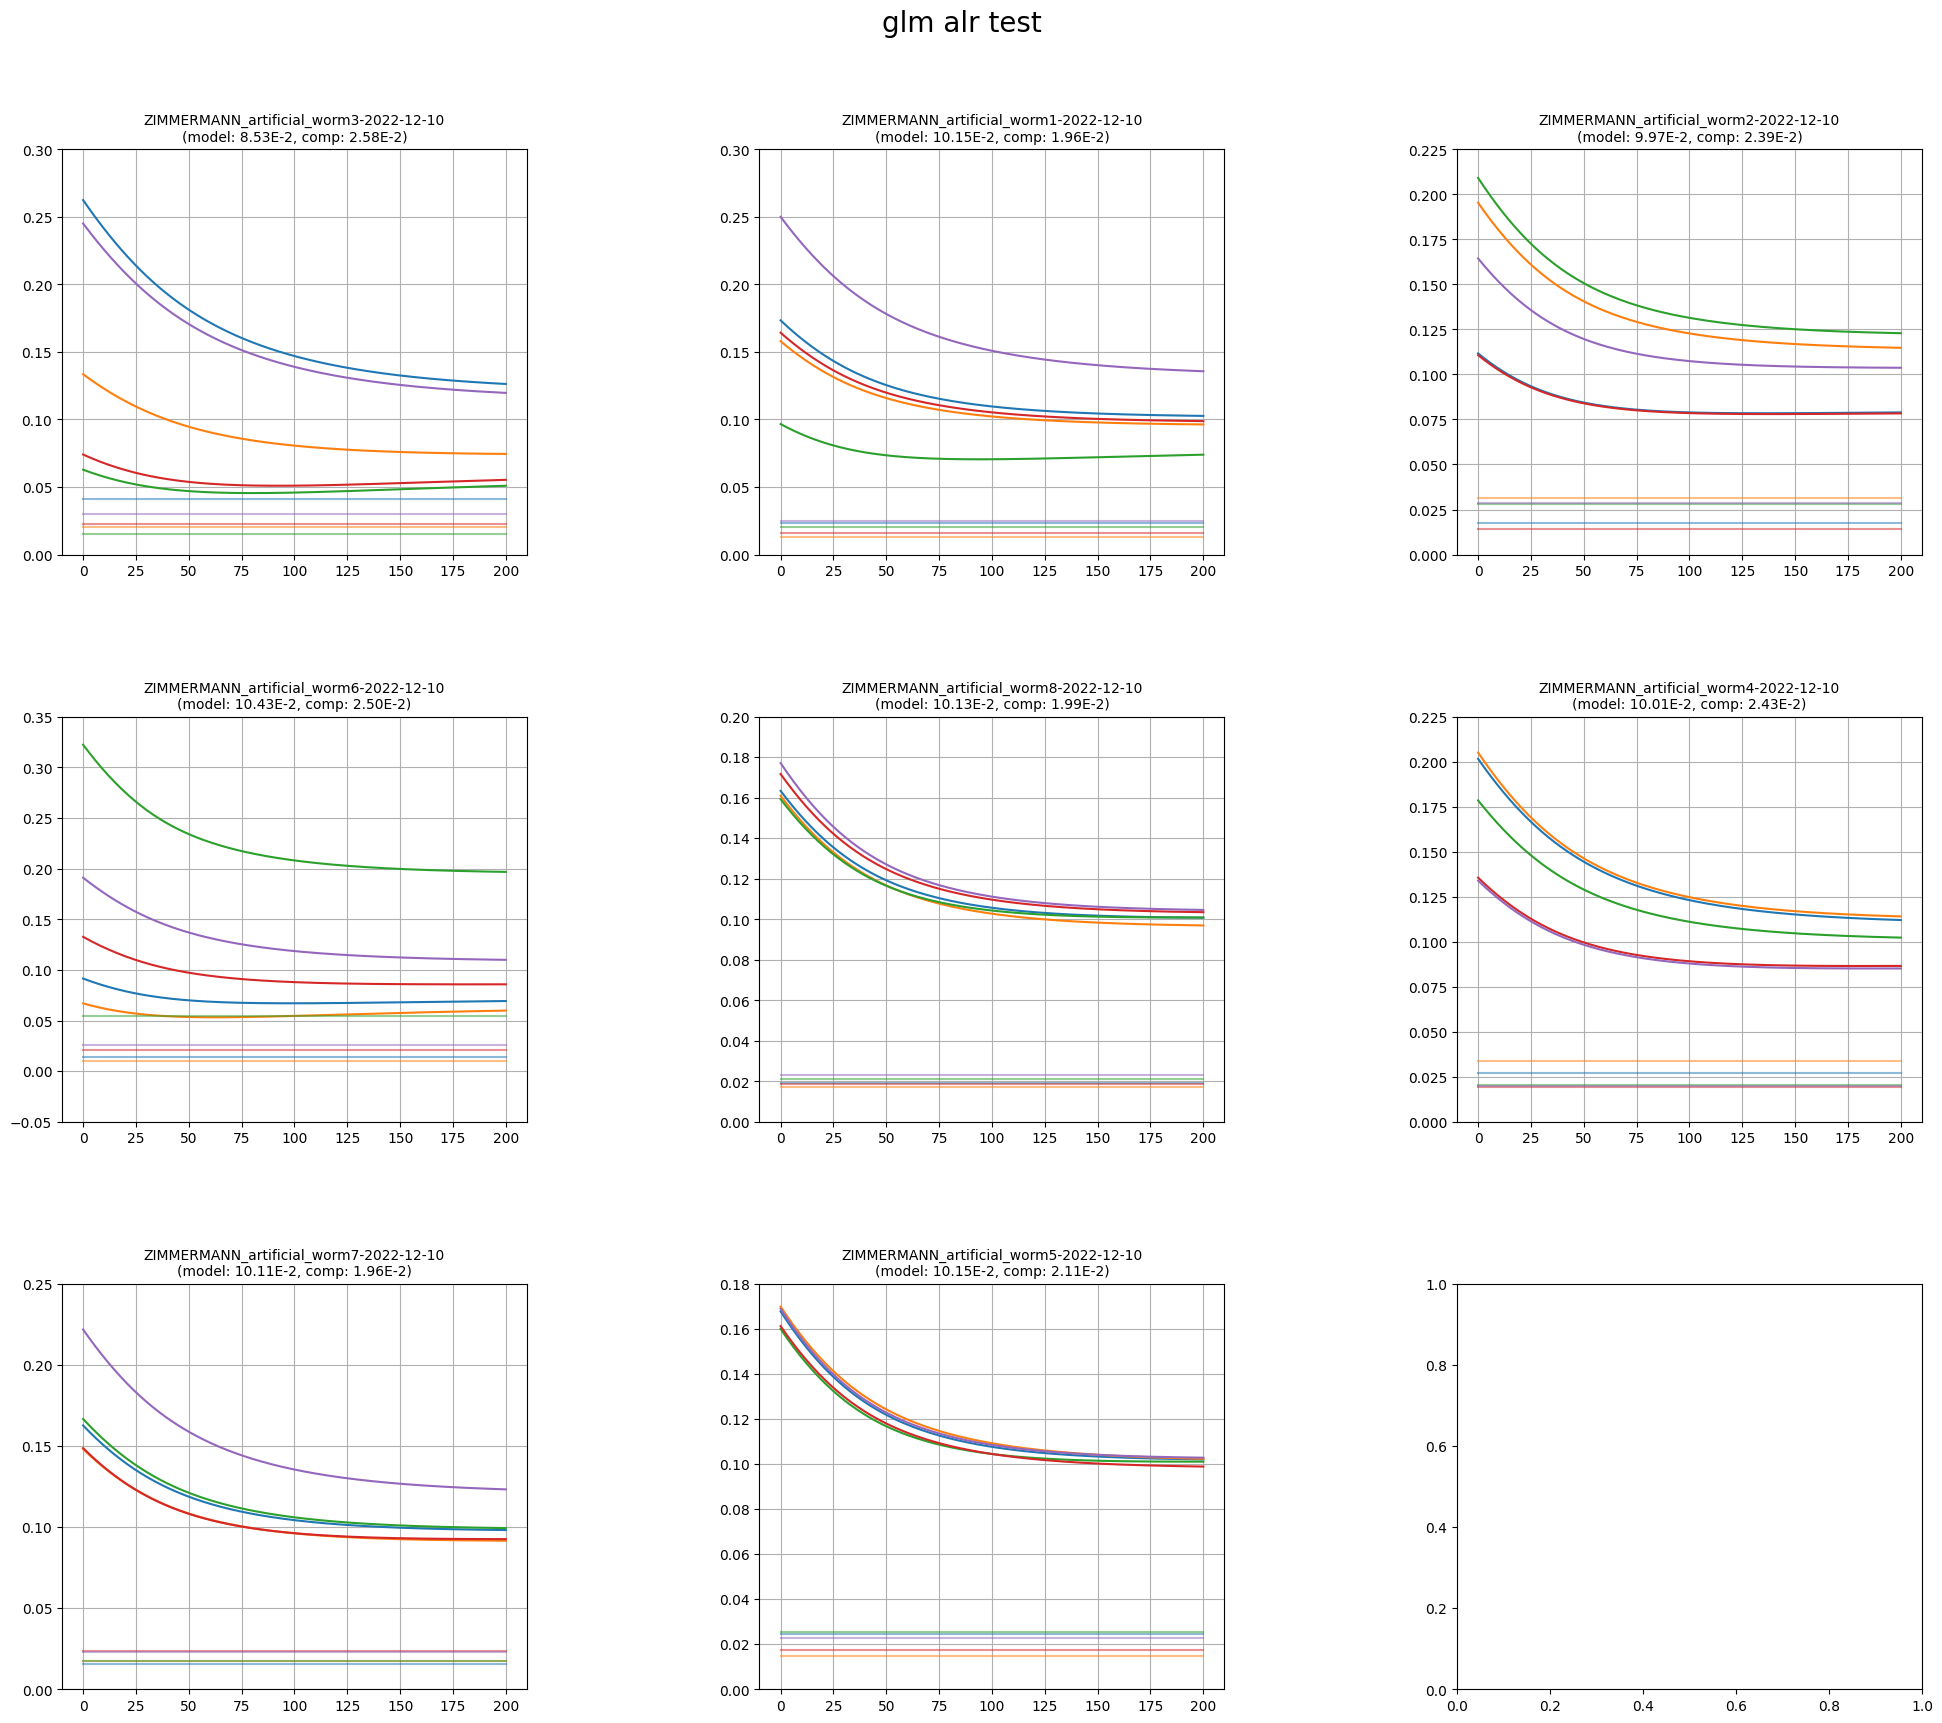

In [8]:
plot_utils.plot_losses(filenames_art, glm_models_losses_art, [loss[:, None] * np.ones((1, glm_models_losses_art[0].shape[1])) for loss in alr_models_losses_art], 'glm alr test')

In [9]:
# hgm art

hgm_models_scores_art = list()
hgm_models_losses_art = list()
hgm_models_losses_tr_art = list()
# hgm_models_params_art = list()
__hgm_models_grads_art = list()

for i in range(len(filenames_art)):
	print(f'{i + 1}/{len(filenames_art)}: {filenames_art[i]}  ', end='')

	splits = list(StratifiedKFold(n_splits=5).split(np.zeros(eigenworms_art[i].values.shape[0]), discrete_states_art[i]['REV'].values))

	neuron_scores_per_split, losses_per_split, losses_tr_per_split, __grads_per_split = train_numerical_model(hgm, splits,
																											  jnp.array(eigenworms_art[i].values),
																											  jnp.array(traces_residual_art[i].values),
																											  jnp.array(modes_manifold_art[i].values))

	hgm_models_scores_art.append(neuron_scores_per_split)
	hgm_models_losses_art.append(losses_per_split)
	hgm_models_losses_tr_art.append(losses_tr_per_split)
	__hgm_models_grads_art.append(__grads_per_split)

1/8: ZIMMERMANN_artificial_worm3-2022-12-10_no_image_data  2/8: ZIMMERMANN_artificial_worm1-2022-12-10_no_image_data  3/8: ZIMMERMANN_artificial_worm2-2022-12-10_no_image_data  4/8: ZIMMERMANN_artificial_worm6-2022-12-10_no_image_data  5/8: ZIMMERMANN_artificial_worm8-2022-12-10_no_image_data  6/8: ZIMMERMANN_artificial_worm4-2022-12-10_no_image_data  7/8: ZIMMERMANN_artificial_worm7-2022-12-10_no_image_data  8/8: ZIMMERMANN_artificial_worm5-2022-12-10_no_image_data  

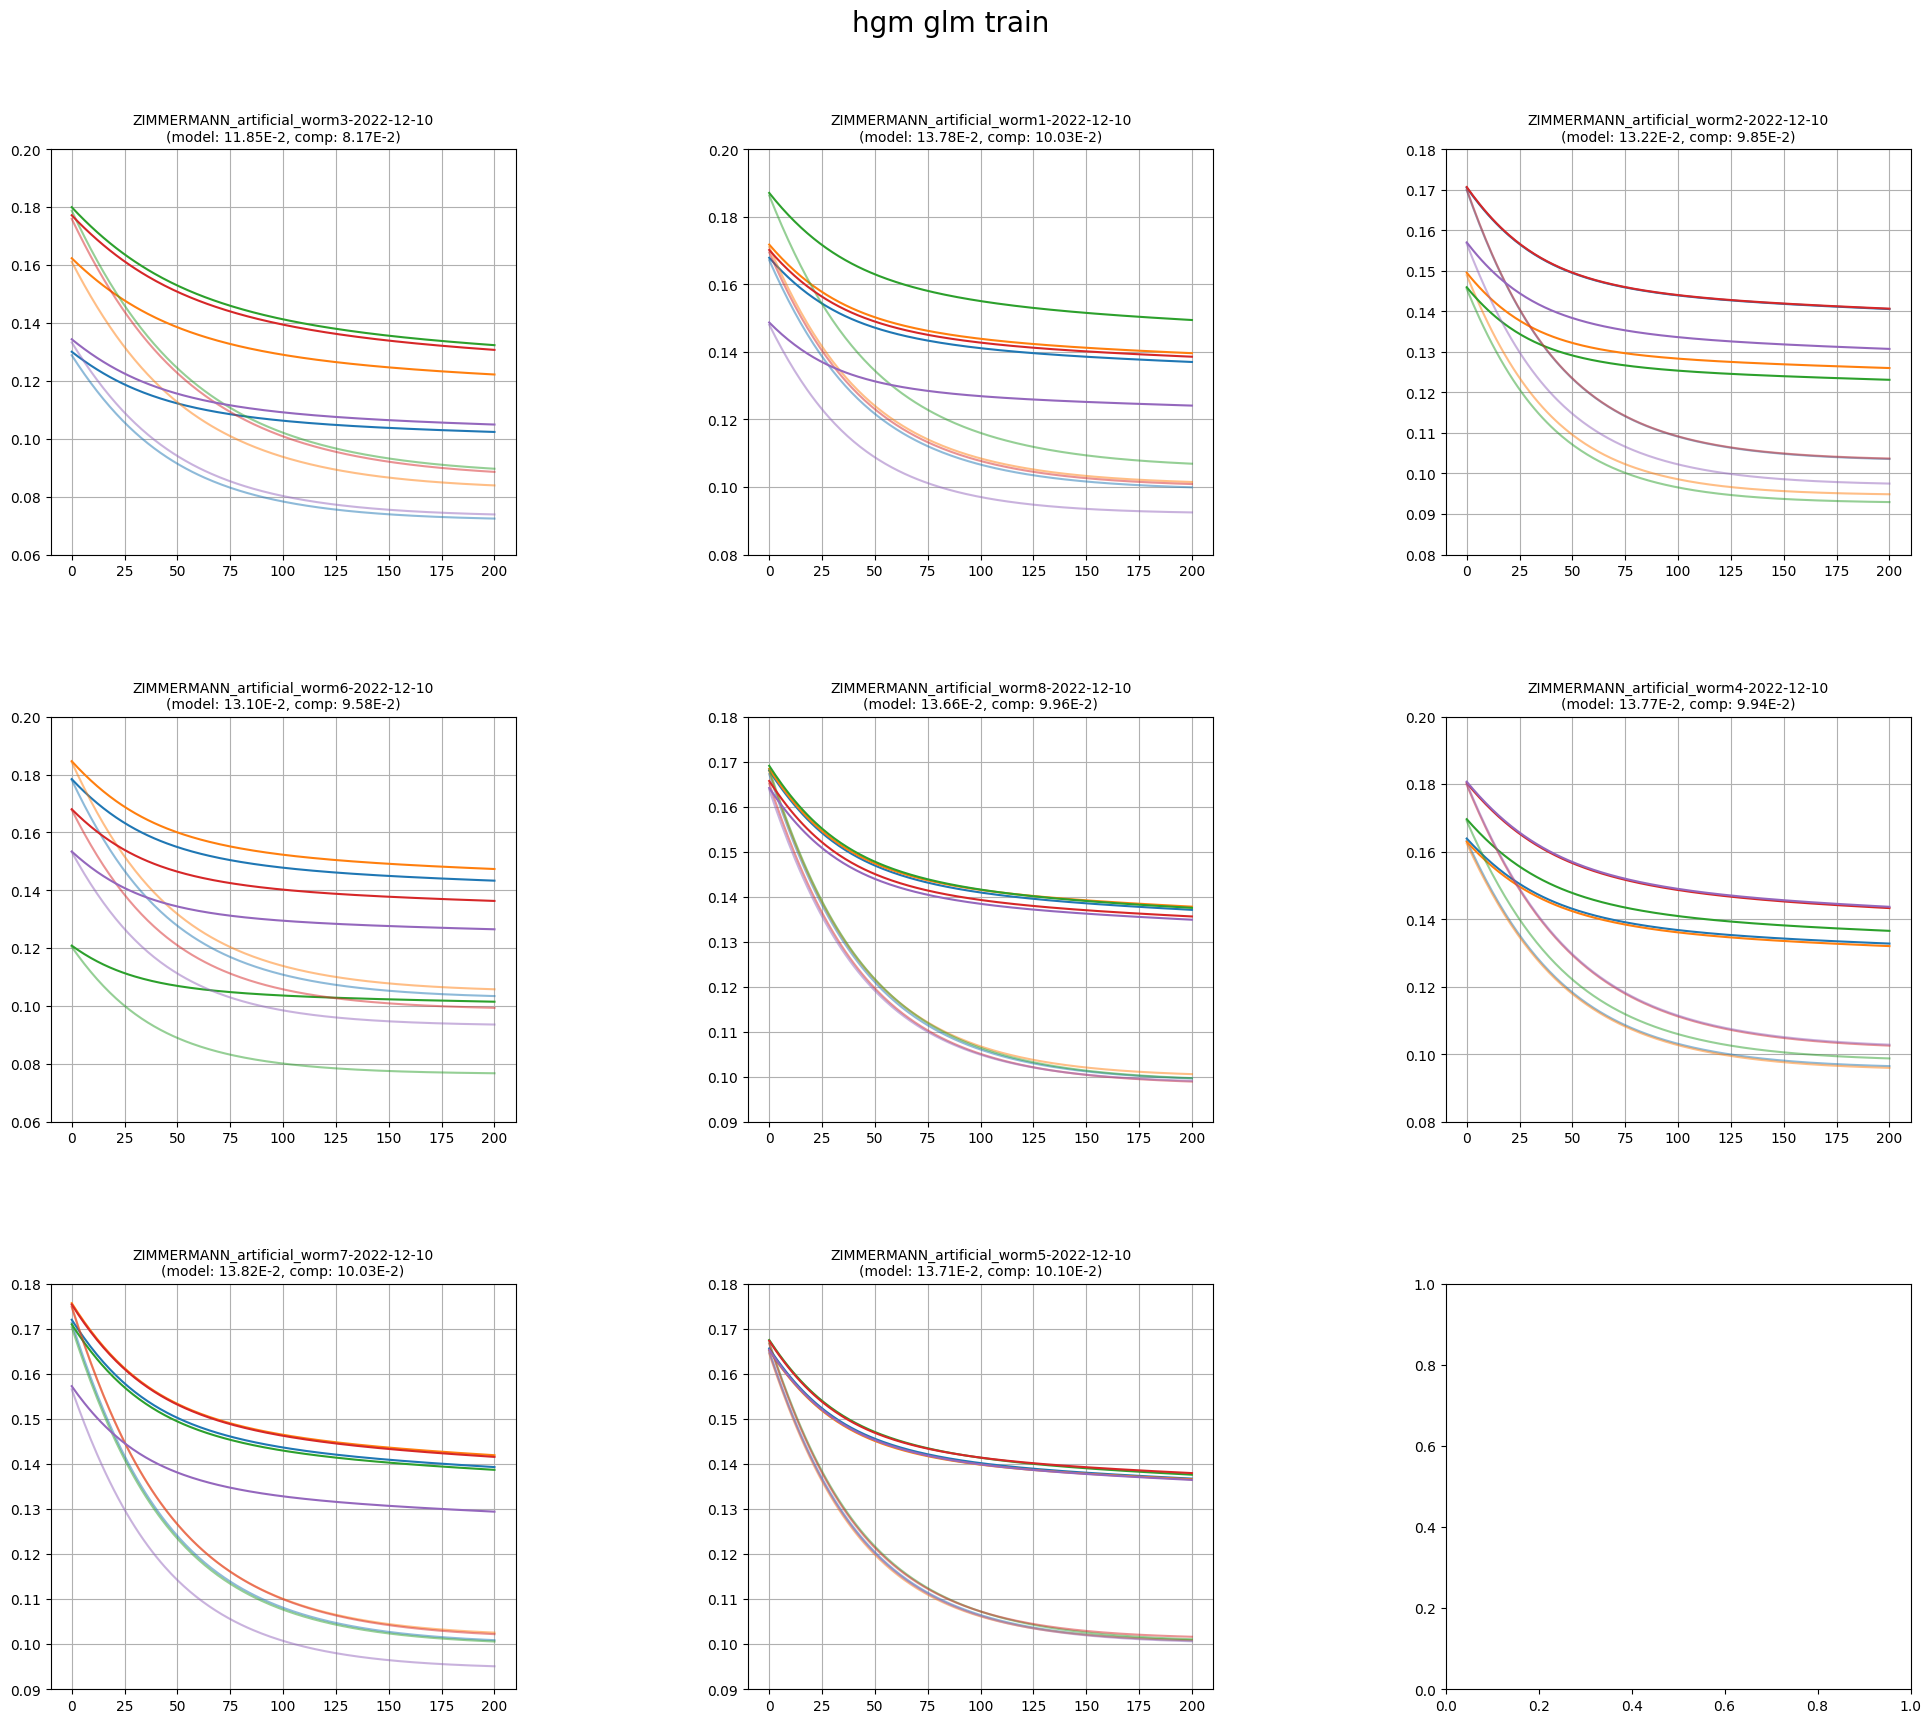

In [10]:
plot_utils.plot_losses(filenames_art, hgm_models_losses_tr_art, glm_models_losses_tr_art, 'hgm glm train')

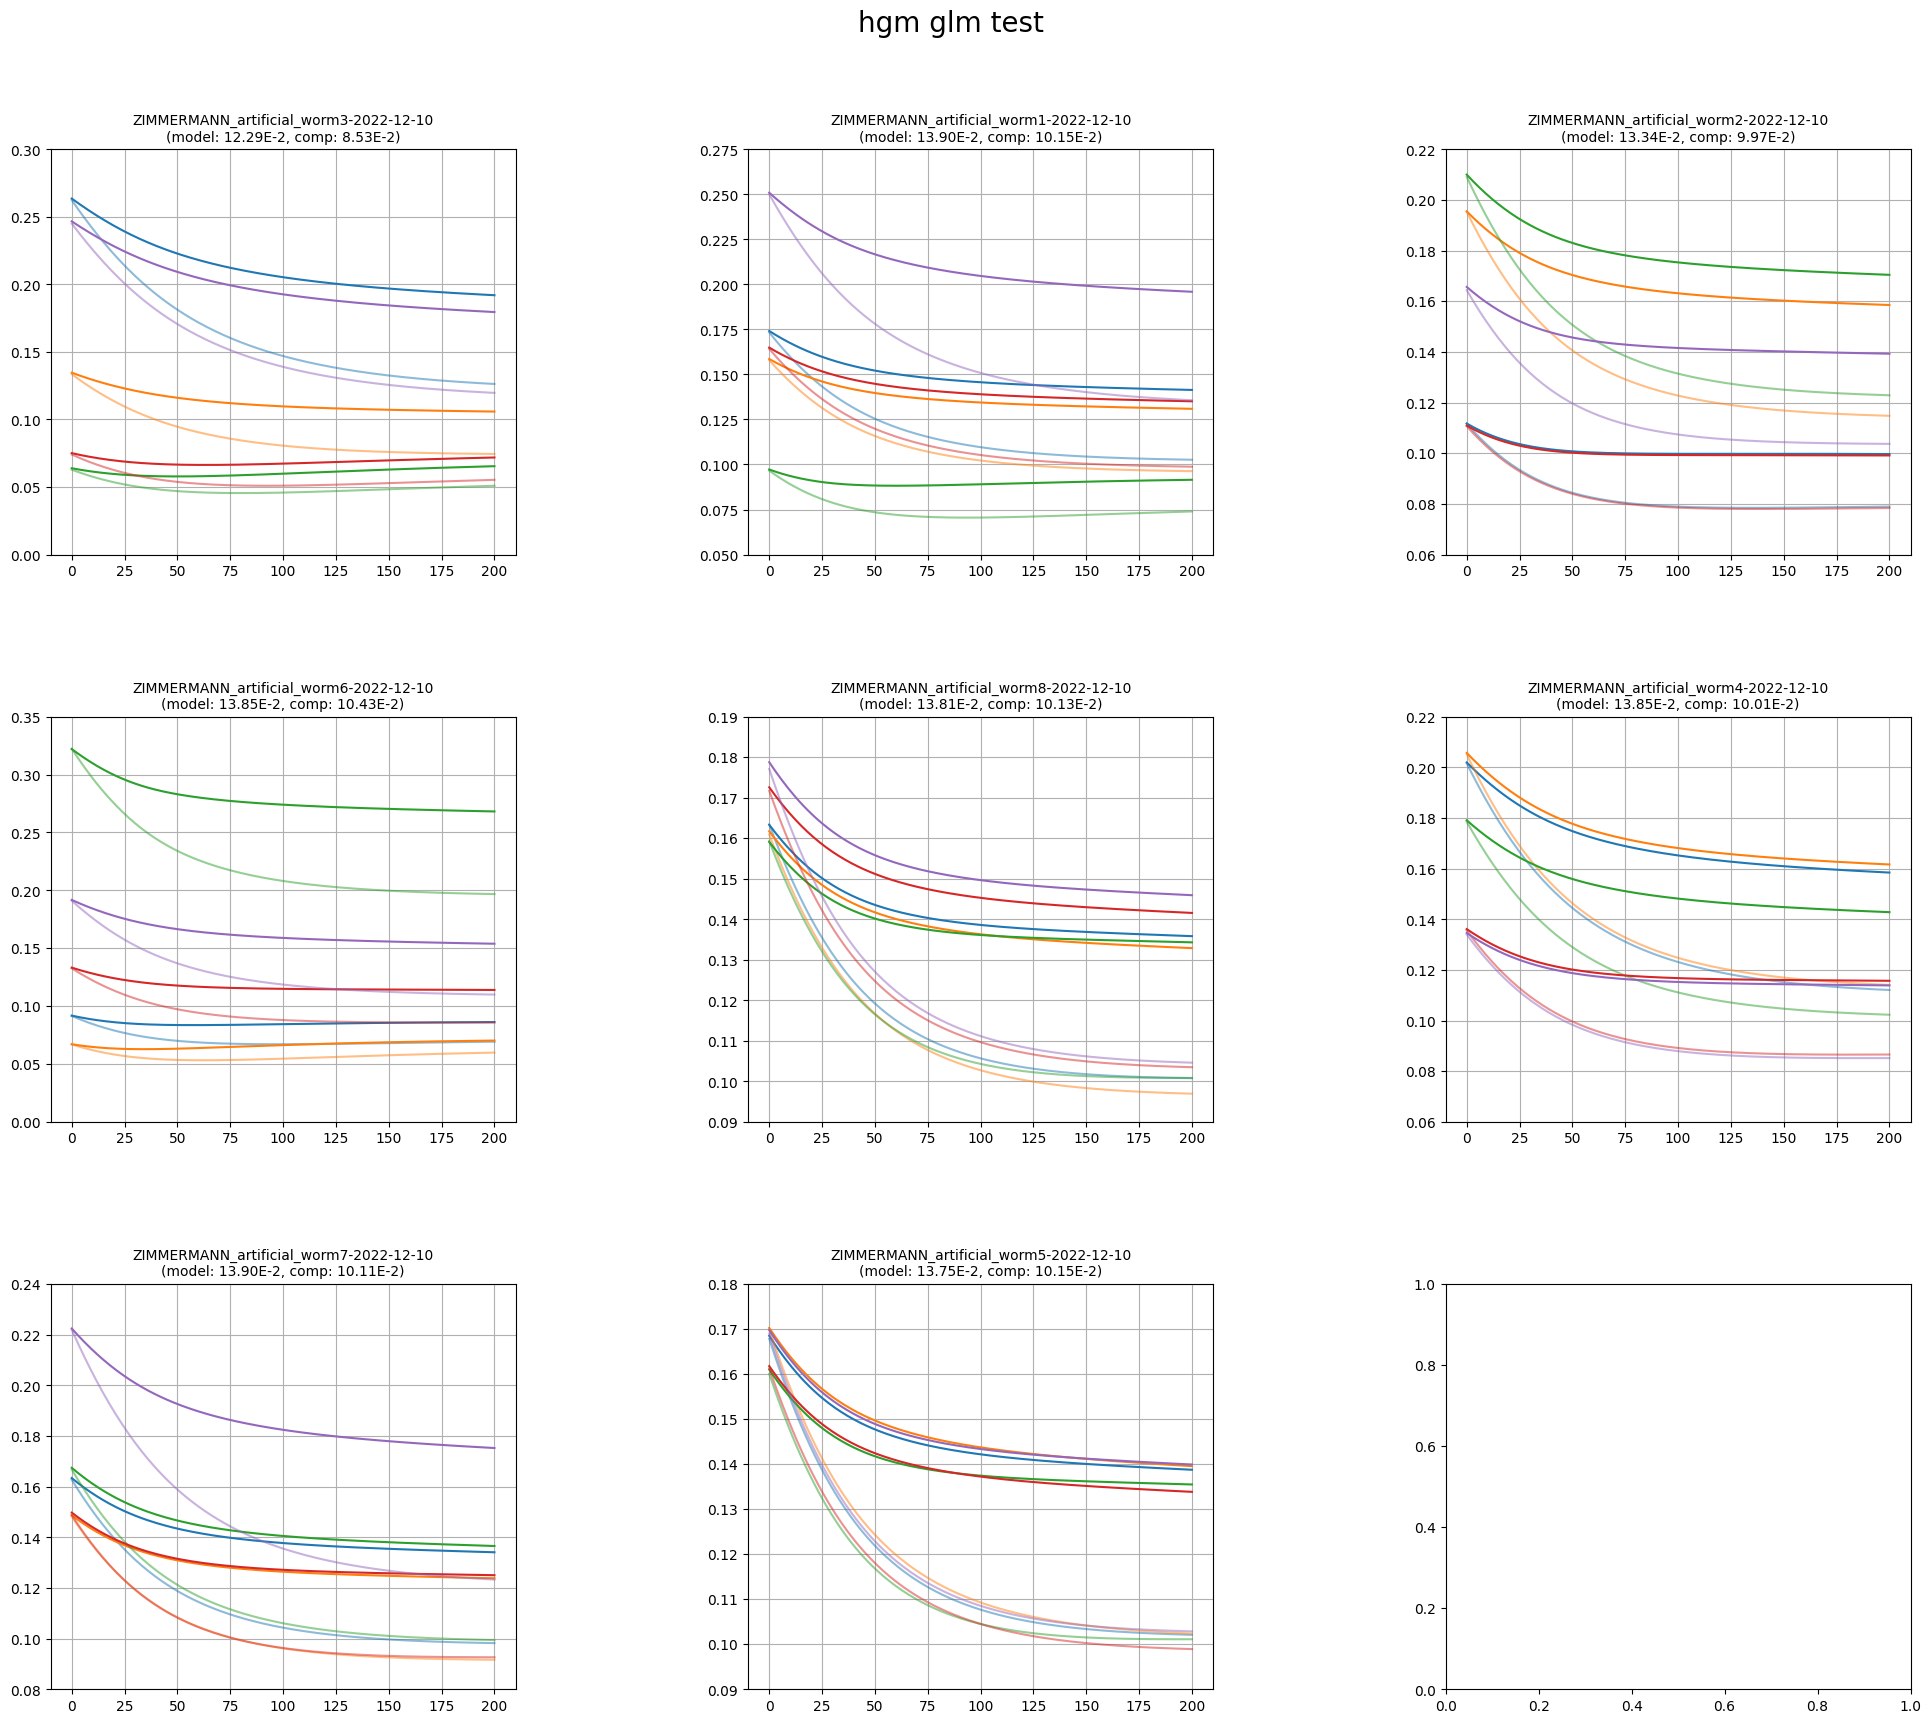

In [11]:
plot_utils.plot_losses(filenames_art, hgm_models_losses_art, glm_models_losses_art, 'hgm glm test')

In [12]:
# assemble art

neurons_labels_art = [traces_art[i].columns for i in range(len(filenames_art))]

# unique_labels_art = sorted(list(set([l for label in neurons_labels_art for l in label])))
# unique_labels_filtered_art = [label for label in unique_labels_art if label != '' and label[-1] != '_']

neuron_scores_art = dict()
glm_models_avg_scores_art = [np.mean(scores, axis=0) for scores in glm_models_scores_art]
hgm_models_avg_scores_art = [np.mean(scores, axis=0) for scores in hgm_models_scores_art]
for label_list, score_glm_list, score_hgm_list in zip(neurons_labels_art, glm_models_avg_scores_art, hgm_models_avg_scores_art):
	for i in range(len(label_list)):
		label = label_list[i]
		if label == '' or label[-1] == '_': continue

		score_glm_new, score_hgm_new = np.array(score_glm_list[i]), np.array(score_hgm_list[i])
		if len(score_hgm_new.shape) == 0:
			score_glm_new = score_glm_new.reshape(1, 1)
			score_hgm_new = score_hgm_new.reshape(1, 1)
		if label not in neuron_scores_art.keys():
			neuron_scores_art[label] = (score_glm_new, score_hgm_new)
		else:
			score_glm_prev, score_hgm_prev = neuron_scores_art[label]
			neuron_scores_art[label] = (np.vstack([score_glm_prev, score_glm_new]), np.vstack([score_hgm_prev, score_hgm_new]))

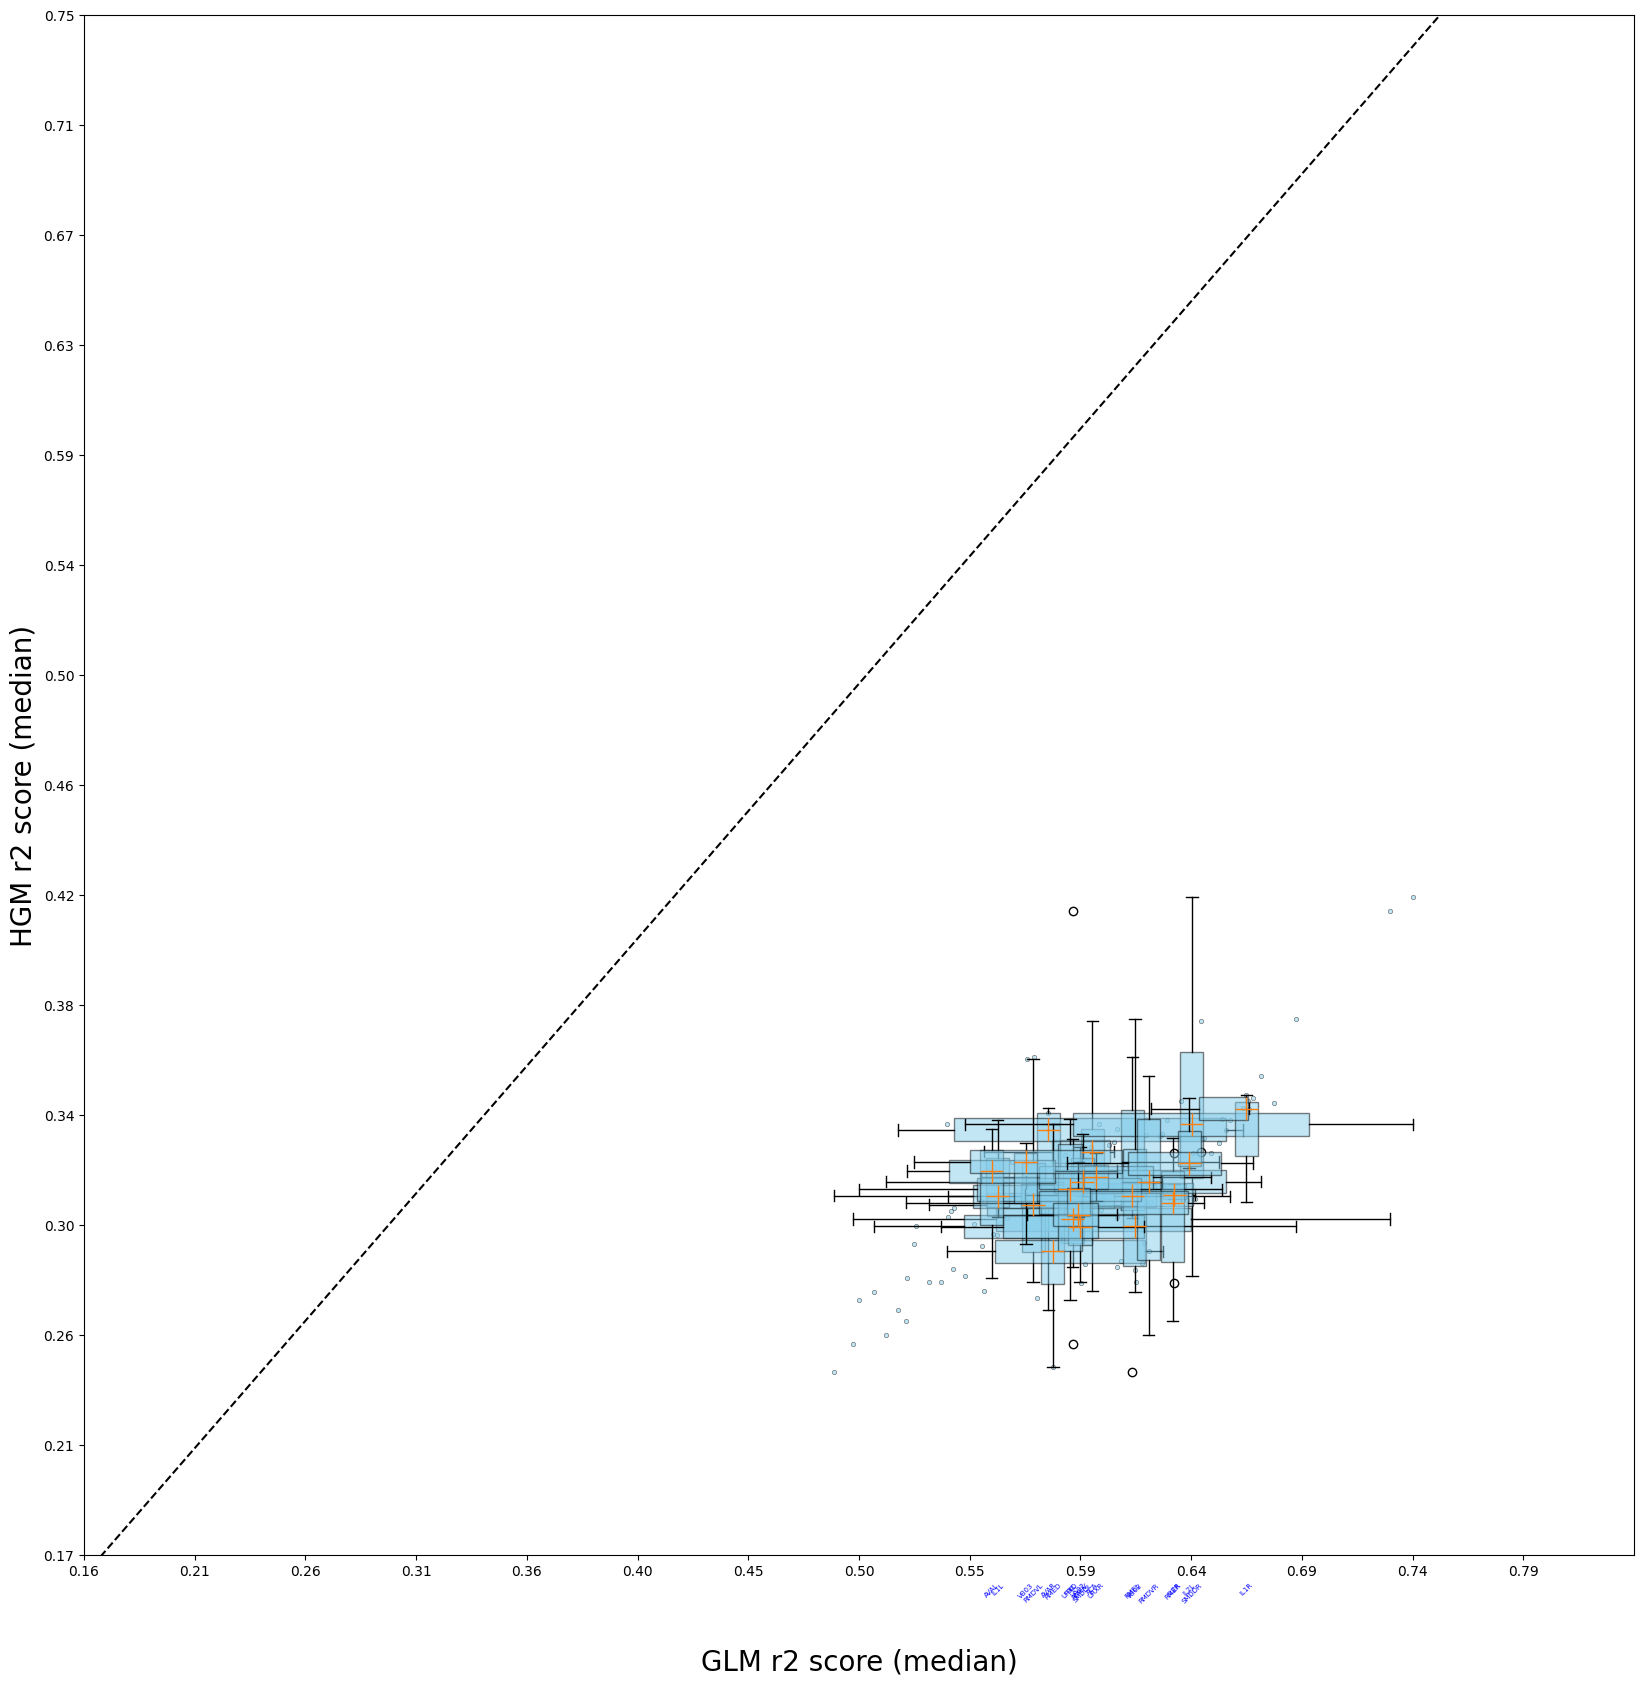

In [13]:
# plot art

plot_utils.plot_performance_plot(neuron_scores_art, None, None, save=True)

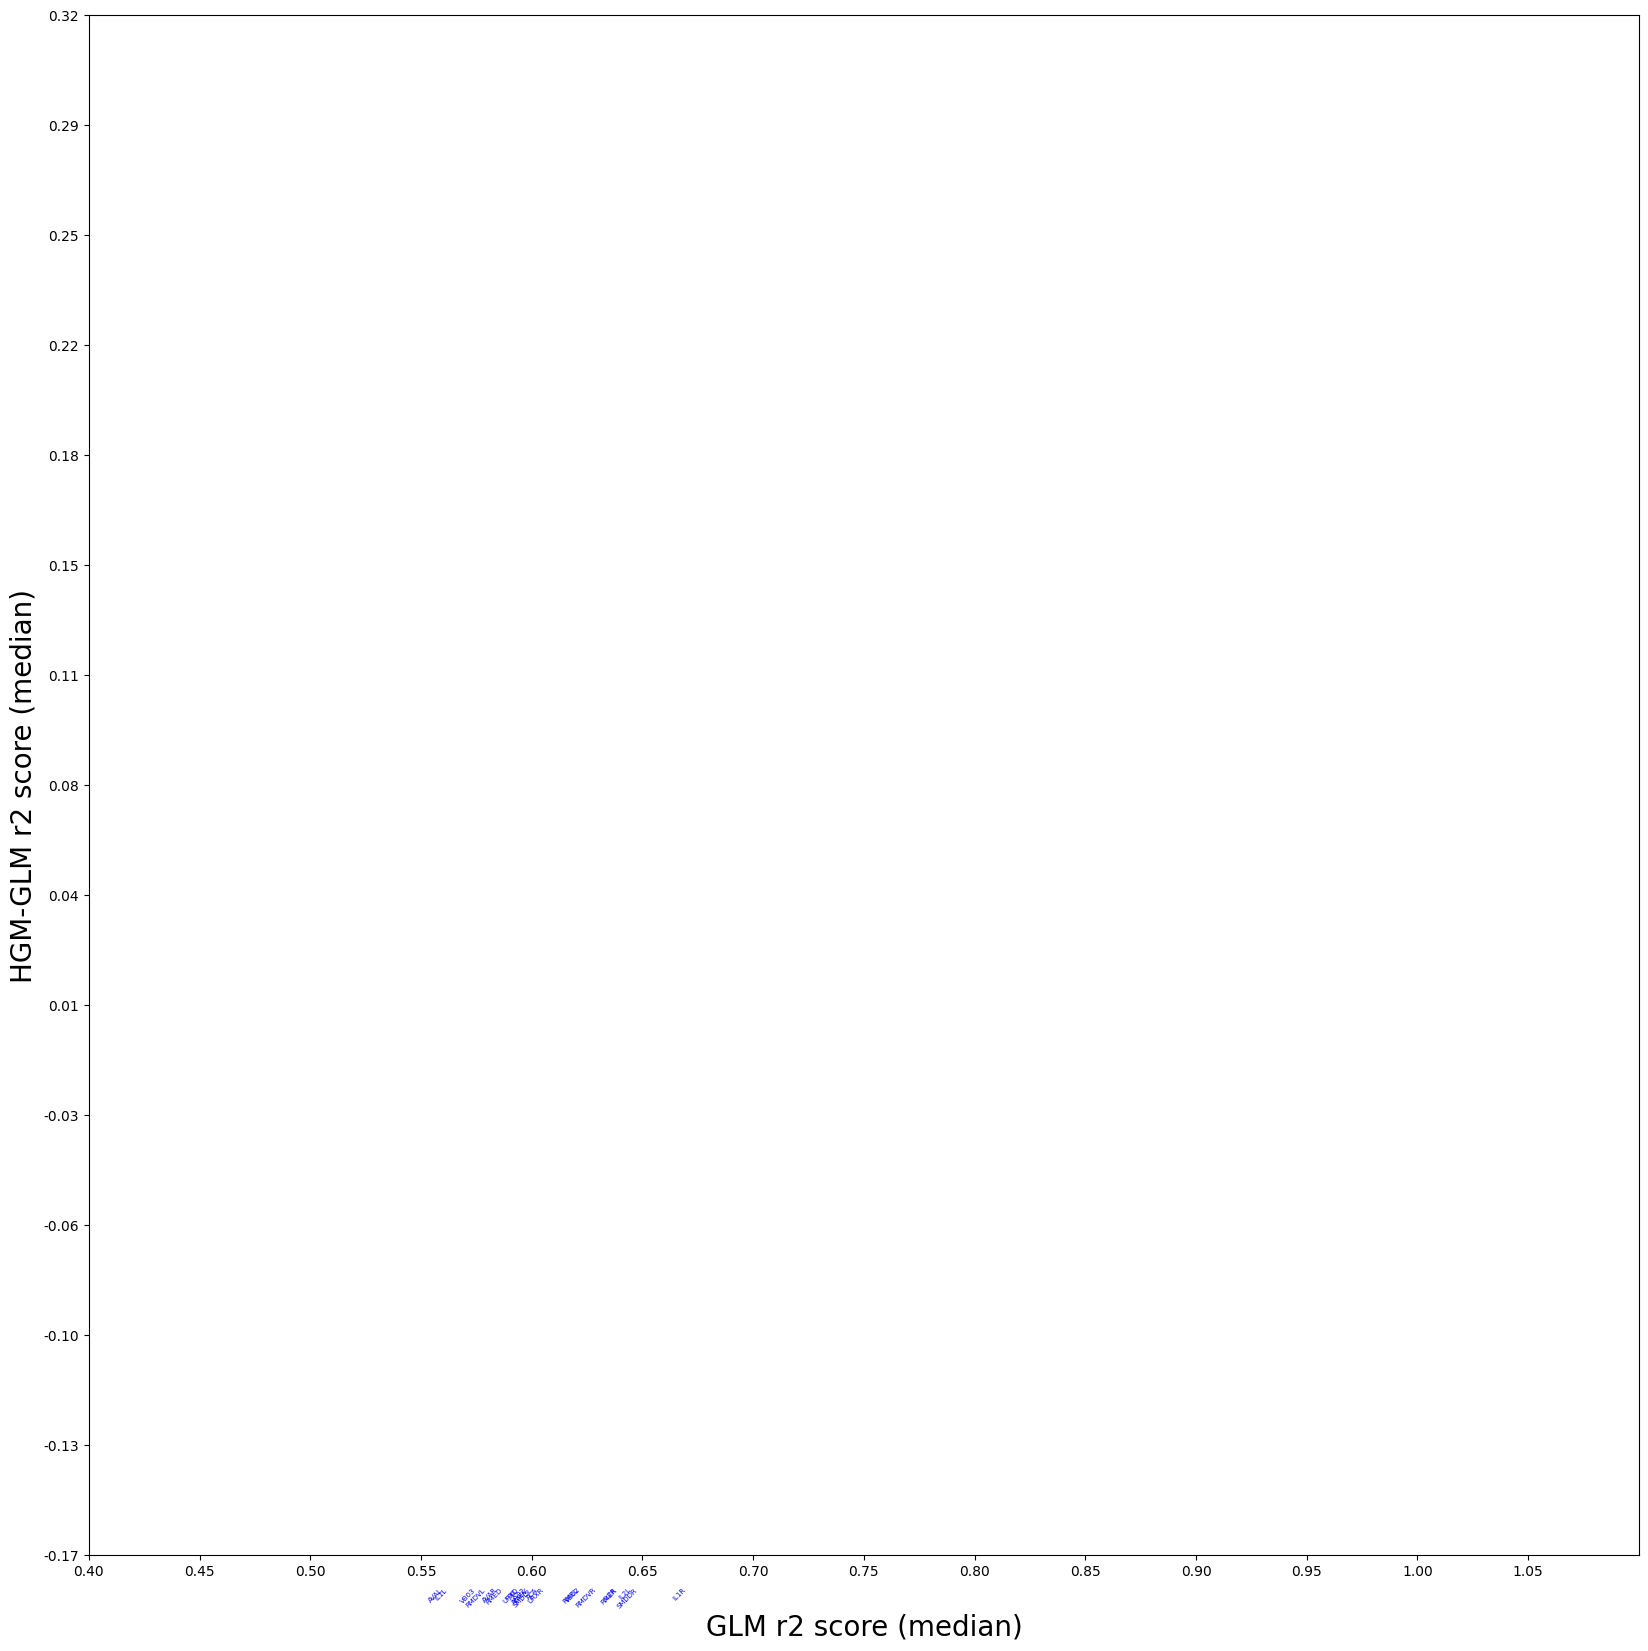

In [14]:
# plot art

plot_utils.plot_improvement_plot(neuron_scores_art, None, (0.5, 1, -0.1, 0.25), save=True)

# ARTIFICIAL DATA END

In [15]:
if False: raise Exception

# GCAMP

### manifold

0.42925363215169243 0.6894067946407938


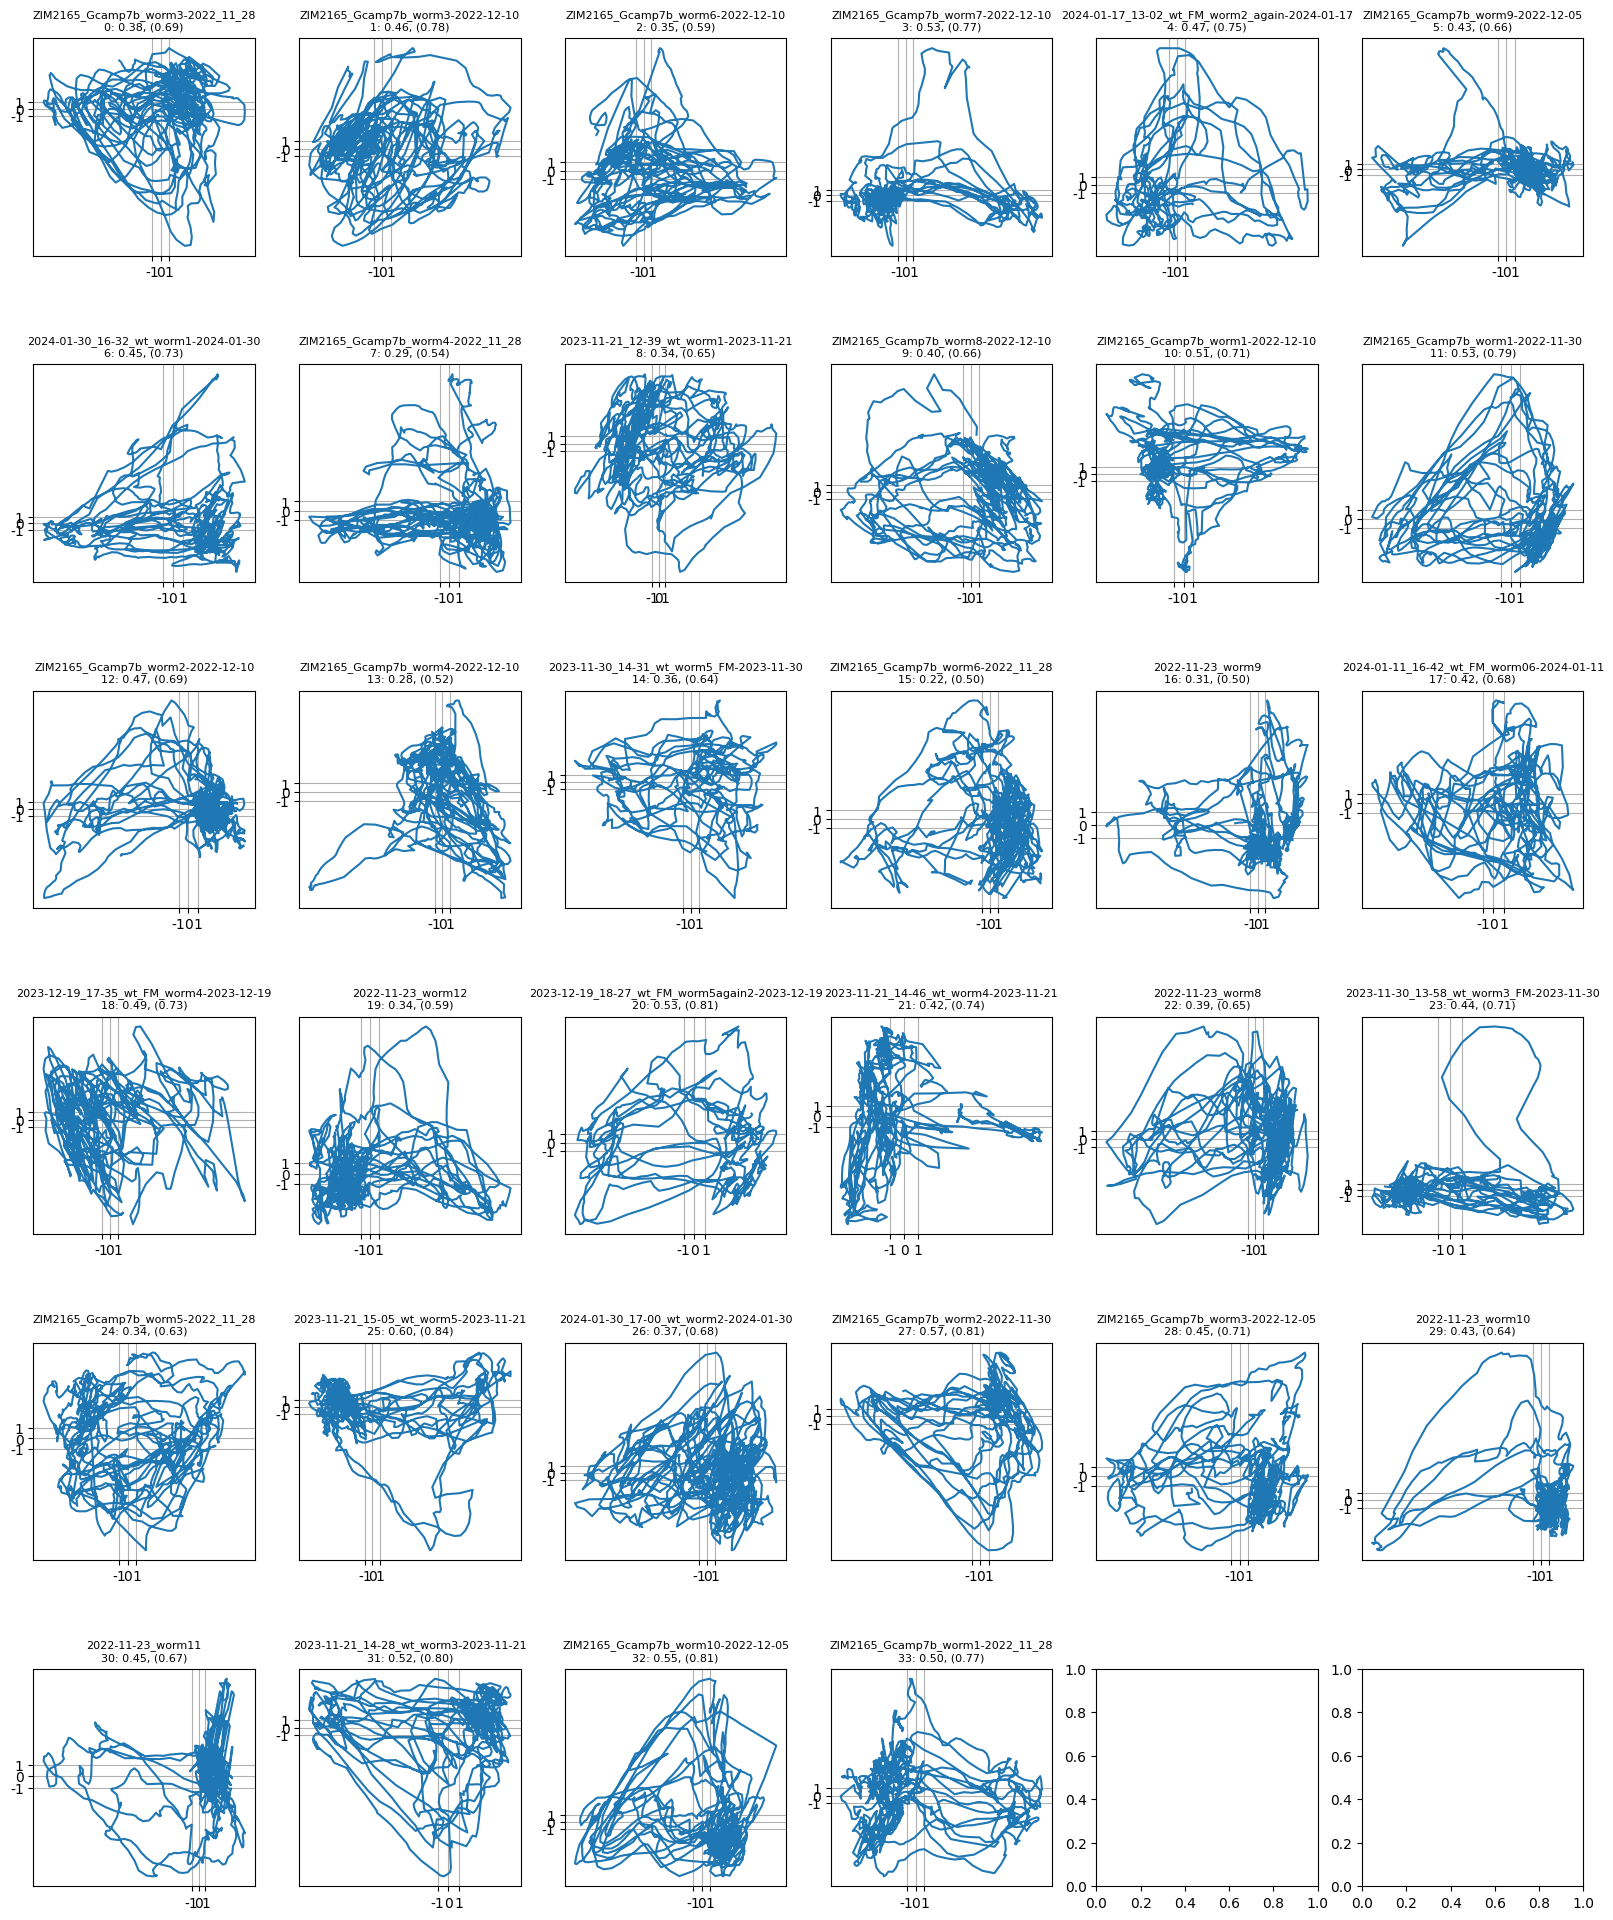

In [16]:
selection = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']

modes_manifold, traces_manifold, cca_loadings_man, vars_expl_man, vars_expl_man_rs = train_utils.get_manifolds(traces,
																											   [ds[selection] for ds in discrete_states],
																											   n_cc=2, n_pc=5)

plot_utils.plot_manifolds(filenames, modes_manifold, vars_expl_man, vars_expl_man_rs)

In [17]:
traces_residual = [pd.DataFrame(data=trace.values - trace_manifold.values, columns=trace.columns) for trace, trace_manifold in zip(traces, traces_manifold)]

### analytical linear regression

In [18]:
alr_models_scores = list()
alr_models_losses = list()
alr_models_losses_tr = list()
for i in range(len(filenames)):
	print(f'{i+1}/{len(filenames)}: {filenames[i]} ', end='')

	splits = list(StratifiedKFold(n_splits=5).split(np.zeros(eigenworms[i].values.shape[0]), discrete_states[i]['REV'].values))

	neuron_score_per_split, loss_per_split, loss_tr_per_split = fit_analytical_model(splits, eigenworms[i].values, traces_residual[i].values)

	alr_models_scores.append(neuron_score_per_split)
	alr_models_losses.append(loss_per_split)
	alr_models_losses_tr.append(loss_tr_per_split)

1/34: ZIM2165_Gcamp7b_worm3-2022_11_28_no_image_data 2/34: ZIM2165_Gcamp7b_worm3-2022-12-10_no_image_data 3/34: ZIM2165_Gcamp7b_worm6-2022-12-10_no_image_data 4/34: ZIM2165_Gcamp7b_worm7-2022-12-10_no_image_data 5/34: 2024-01-17_13-02_wt_FM_worm2_again-2024-01-17_no_image_data 6/34: ZIM2165_Gcamp7b_worm9-2022-12-05_no_image_data 7/34: 2024-01-30_16-32_wt_worm1-2024-01-30_no_image_data 8/34: ZIM2165_Gcamp7b_worm4-2022_11_28_no_image_data 9/34: 2023-11-21_12-39_wt_worm1-2023-11-21_no_image_data 10/34: ZIM2165_Gcamp7b_worm8-2022-12-10_no_image_data 11/34: ZIM2165_Gcamp7b_worm1-2022-12-10_no_image_data 12/34: ZIM2165_Gcamp7b_worm1-2022-11-30_no_image_data 13/34: ZIM2165_Gcamp7b_worm2-2022-12-10_no_image_data 14/34: ZIM2165_Gcamp7b_worm4-2022-12-10_no_image_data 15/34: 2023-11-30_14-31_wt_worm5_FM-2023-11-30_no_image_data 16/34: ZIM2165_Gcamp7b_worm6-2022_11_28_no_image_data 17/34: 2022-11-23_worm9_no_image_data 18/34: 2024-01-11_16-42_wt_FM_worm06-2024-01-11_no_image_data 19/34: 2023-12-19

### GLM

In [19]:
glm_models_scores = list()
glm_models_losses = list()
glm_models_losses_tr = list()
# glm_models_params = list()
__glm_models_grads = list()

for i in range(len(filenames)):
	print(f'{i + 1}/{len(filenames)}: {filenames[i]}  ', end='')

	splits = list(StratifiedKFold(n_splits=5).split(np.zeros(eigenworms[i].values.shape[0]), discrete_states[i]['REV'].values))

	neuron_scores_per_split, losses_per_split, losses_tr_per_split, __grads_per_split = train_numerical_model(glm, splits,
																												 jnp.array(eigenworms[i].values),
																												 jnp.array(traces_residual[i].values),
																												 None)

	glm_models_scores.append(neuron_scores_per_split)
	glm_models_losses.append(losses_per_split)
	glm_models_losses_tr.append(losses_tr_per_split)
	__glm_models_grads.append(__grads_per_split)

1/34: ZIM2165_Gcamp7b_worm3-2022_11_28_no_image_data  2/34: ZIM2165_Gcamp7b_worm3-2022-12-10_no_image_data  3/34: ZIM2165_Gcamp7b_worm6-2022-12-10_no_image_data  4/34: ZIM2165_Gcamp7b_worm7-2022-12-10_no_image_data  5/34: 2024-01-17_13-02_wt_FM_worm2_again-2024-01-17_no_image_data  6/34: ZIM2165_Gcamp7b_worm9-2022-12-05_no_image_data  7/34: 2024-01-30_16-32_wt_worm1-2024-01-30_no_image_data  8/34: ZIM2165_Gcamp7b_worm4-2022_11_28_no_image_data  9/34: 2023-11-21_12-39_wt_worm1-2023-11-21_no_image_data  10/34: ZIM2165_Gcamp7b_worm8-2022-12-10_no_image_data  11/34: ZIM2165_Gcamp7b_worm1-2022-12-10_no_image_data  12/34: ZIM2165_Gcamp7b_worm1-2022-11-30_no_image_data  13/34: ZIM2165_Gcamp7b_worm2-2022-12-10_no_image_data  14/34: ZIM2165_Gcamp7b_worm4-2022-12-10_no_image_data  15/34: 2023-11-30_14-31_wt_worm5_FM-2023-11-30_no_image_data  16/34: ZIM2165_Gcamp7b_worm6-2022_11_28_no_image_data  17/34: 2022-11-23_worm9_no_image_data  18/34: 2024-01-11_16-42_wt_FM_worm06-2024-01-11_no_image_data 

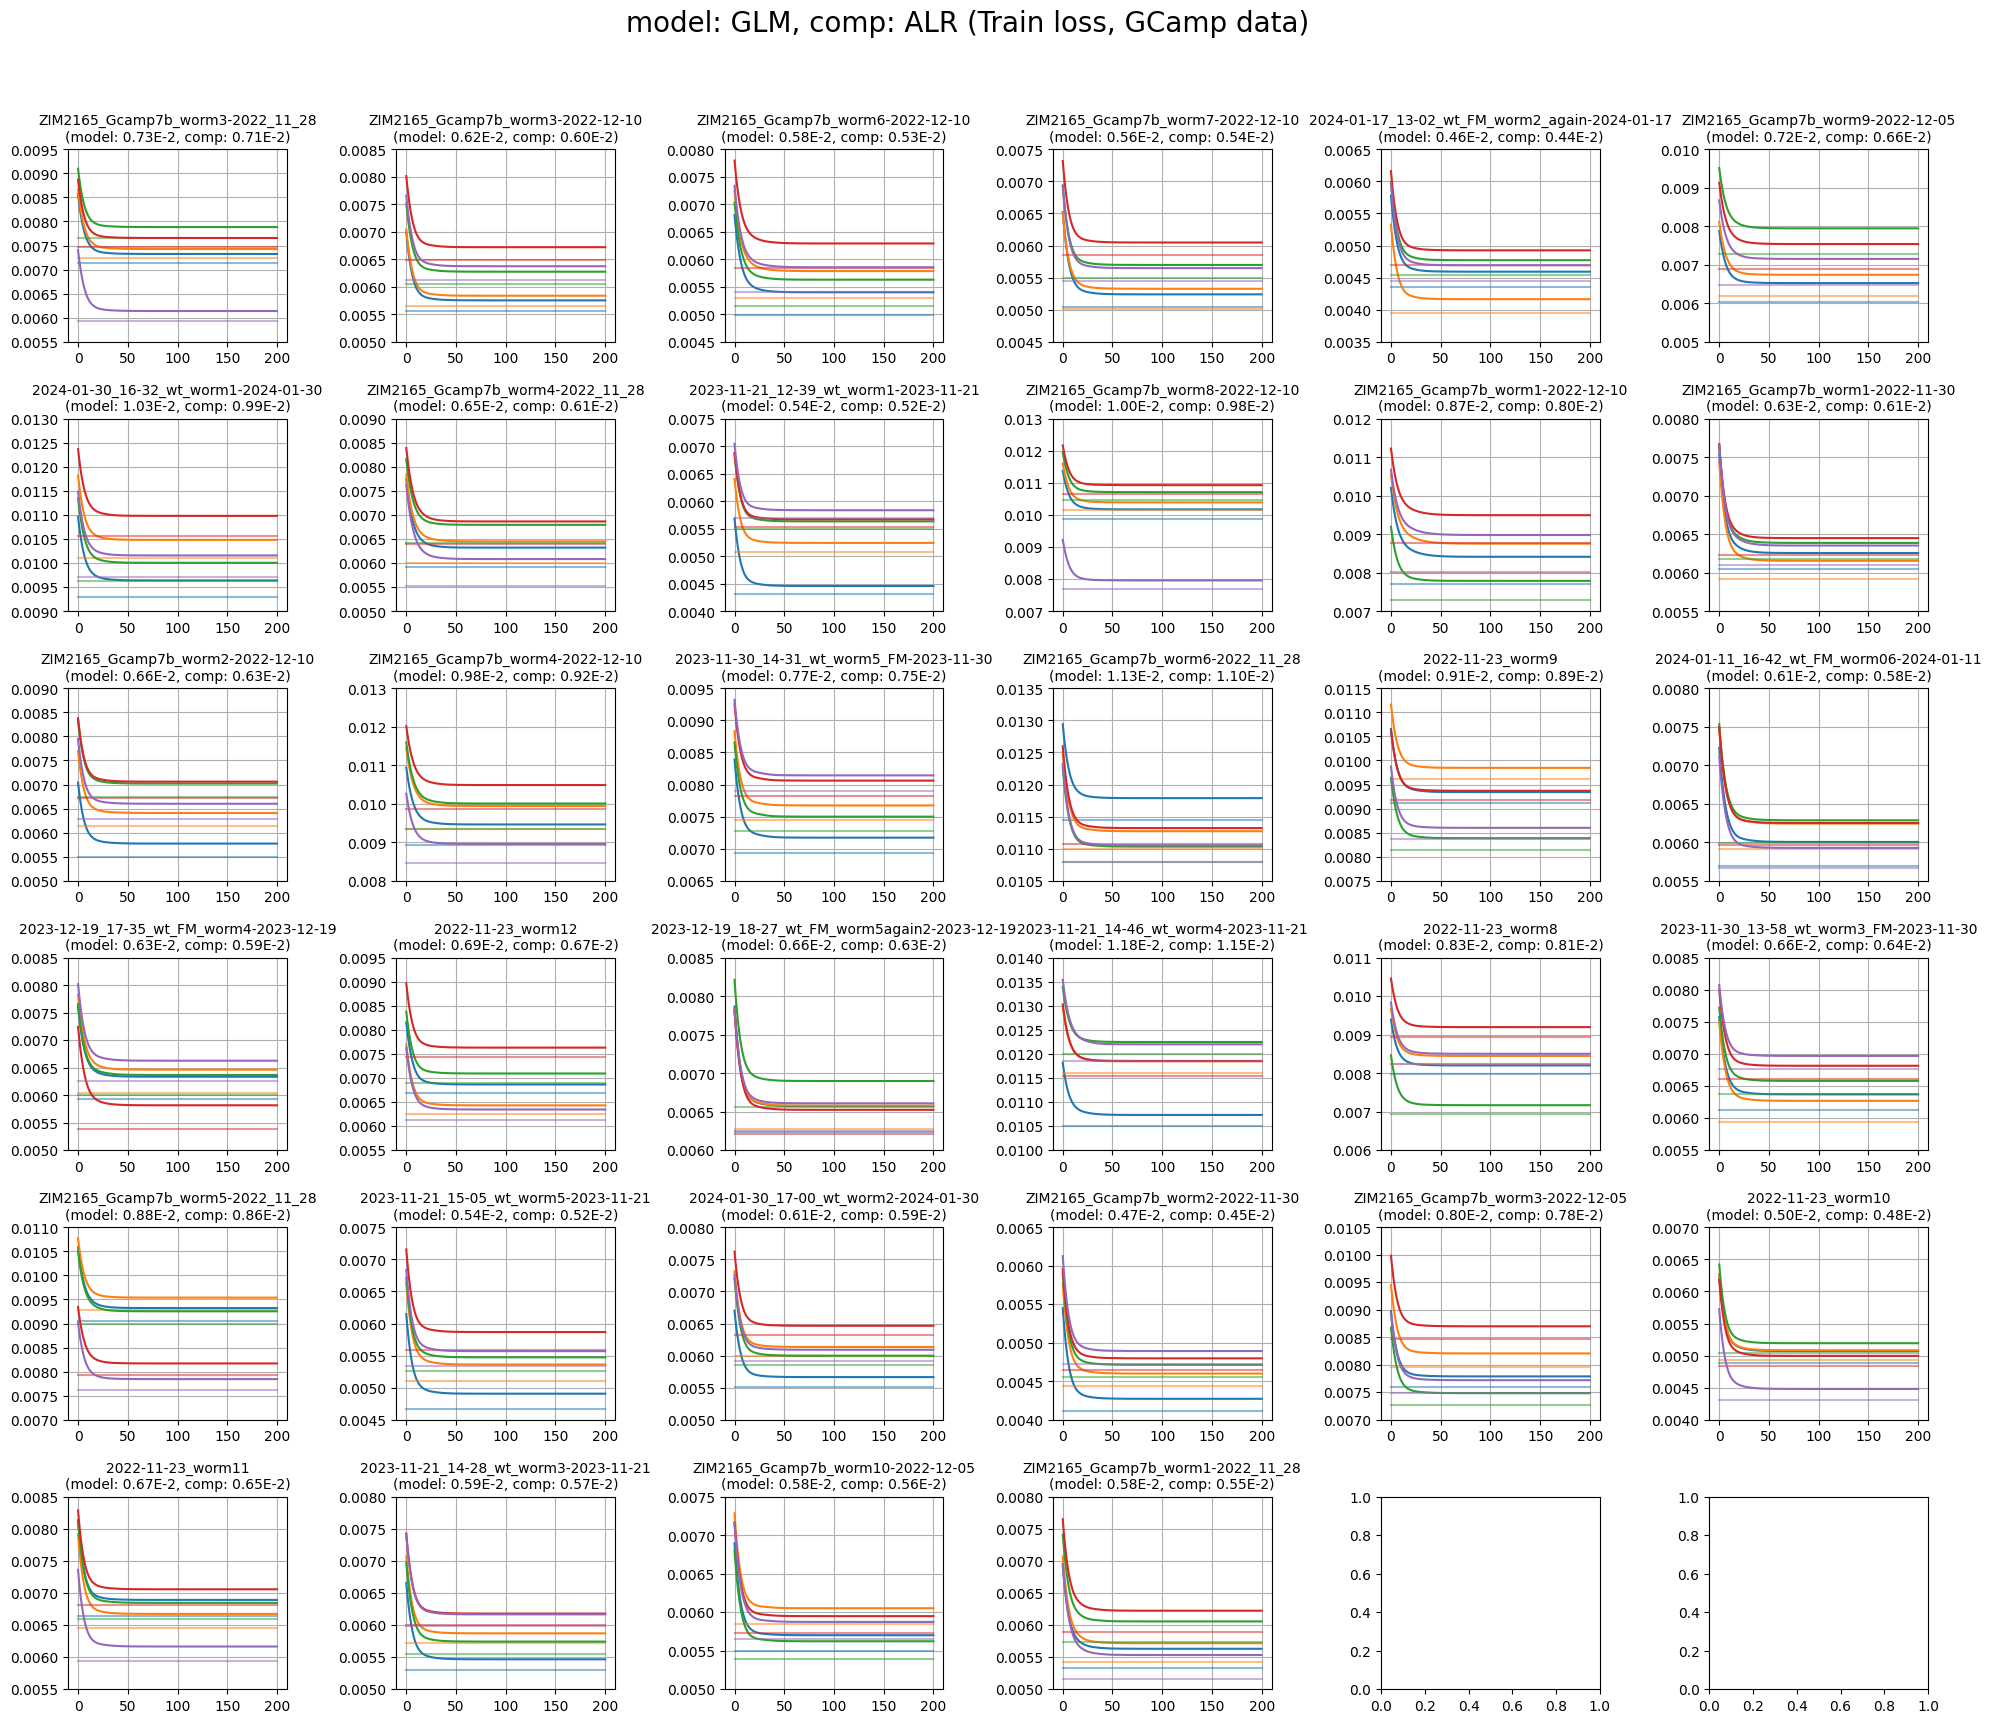

In [20]:
plot_utils.plot_losses(filenames, glm_models_losses_tr, [loss[:, None] * np.ones((1, glm_models_losses_tr[0].shape[1])) for loss in alr_models_losses_tr], 'model: GLM, comp: ALR (Train loss, GCamp data)')

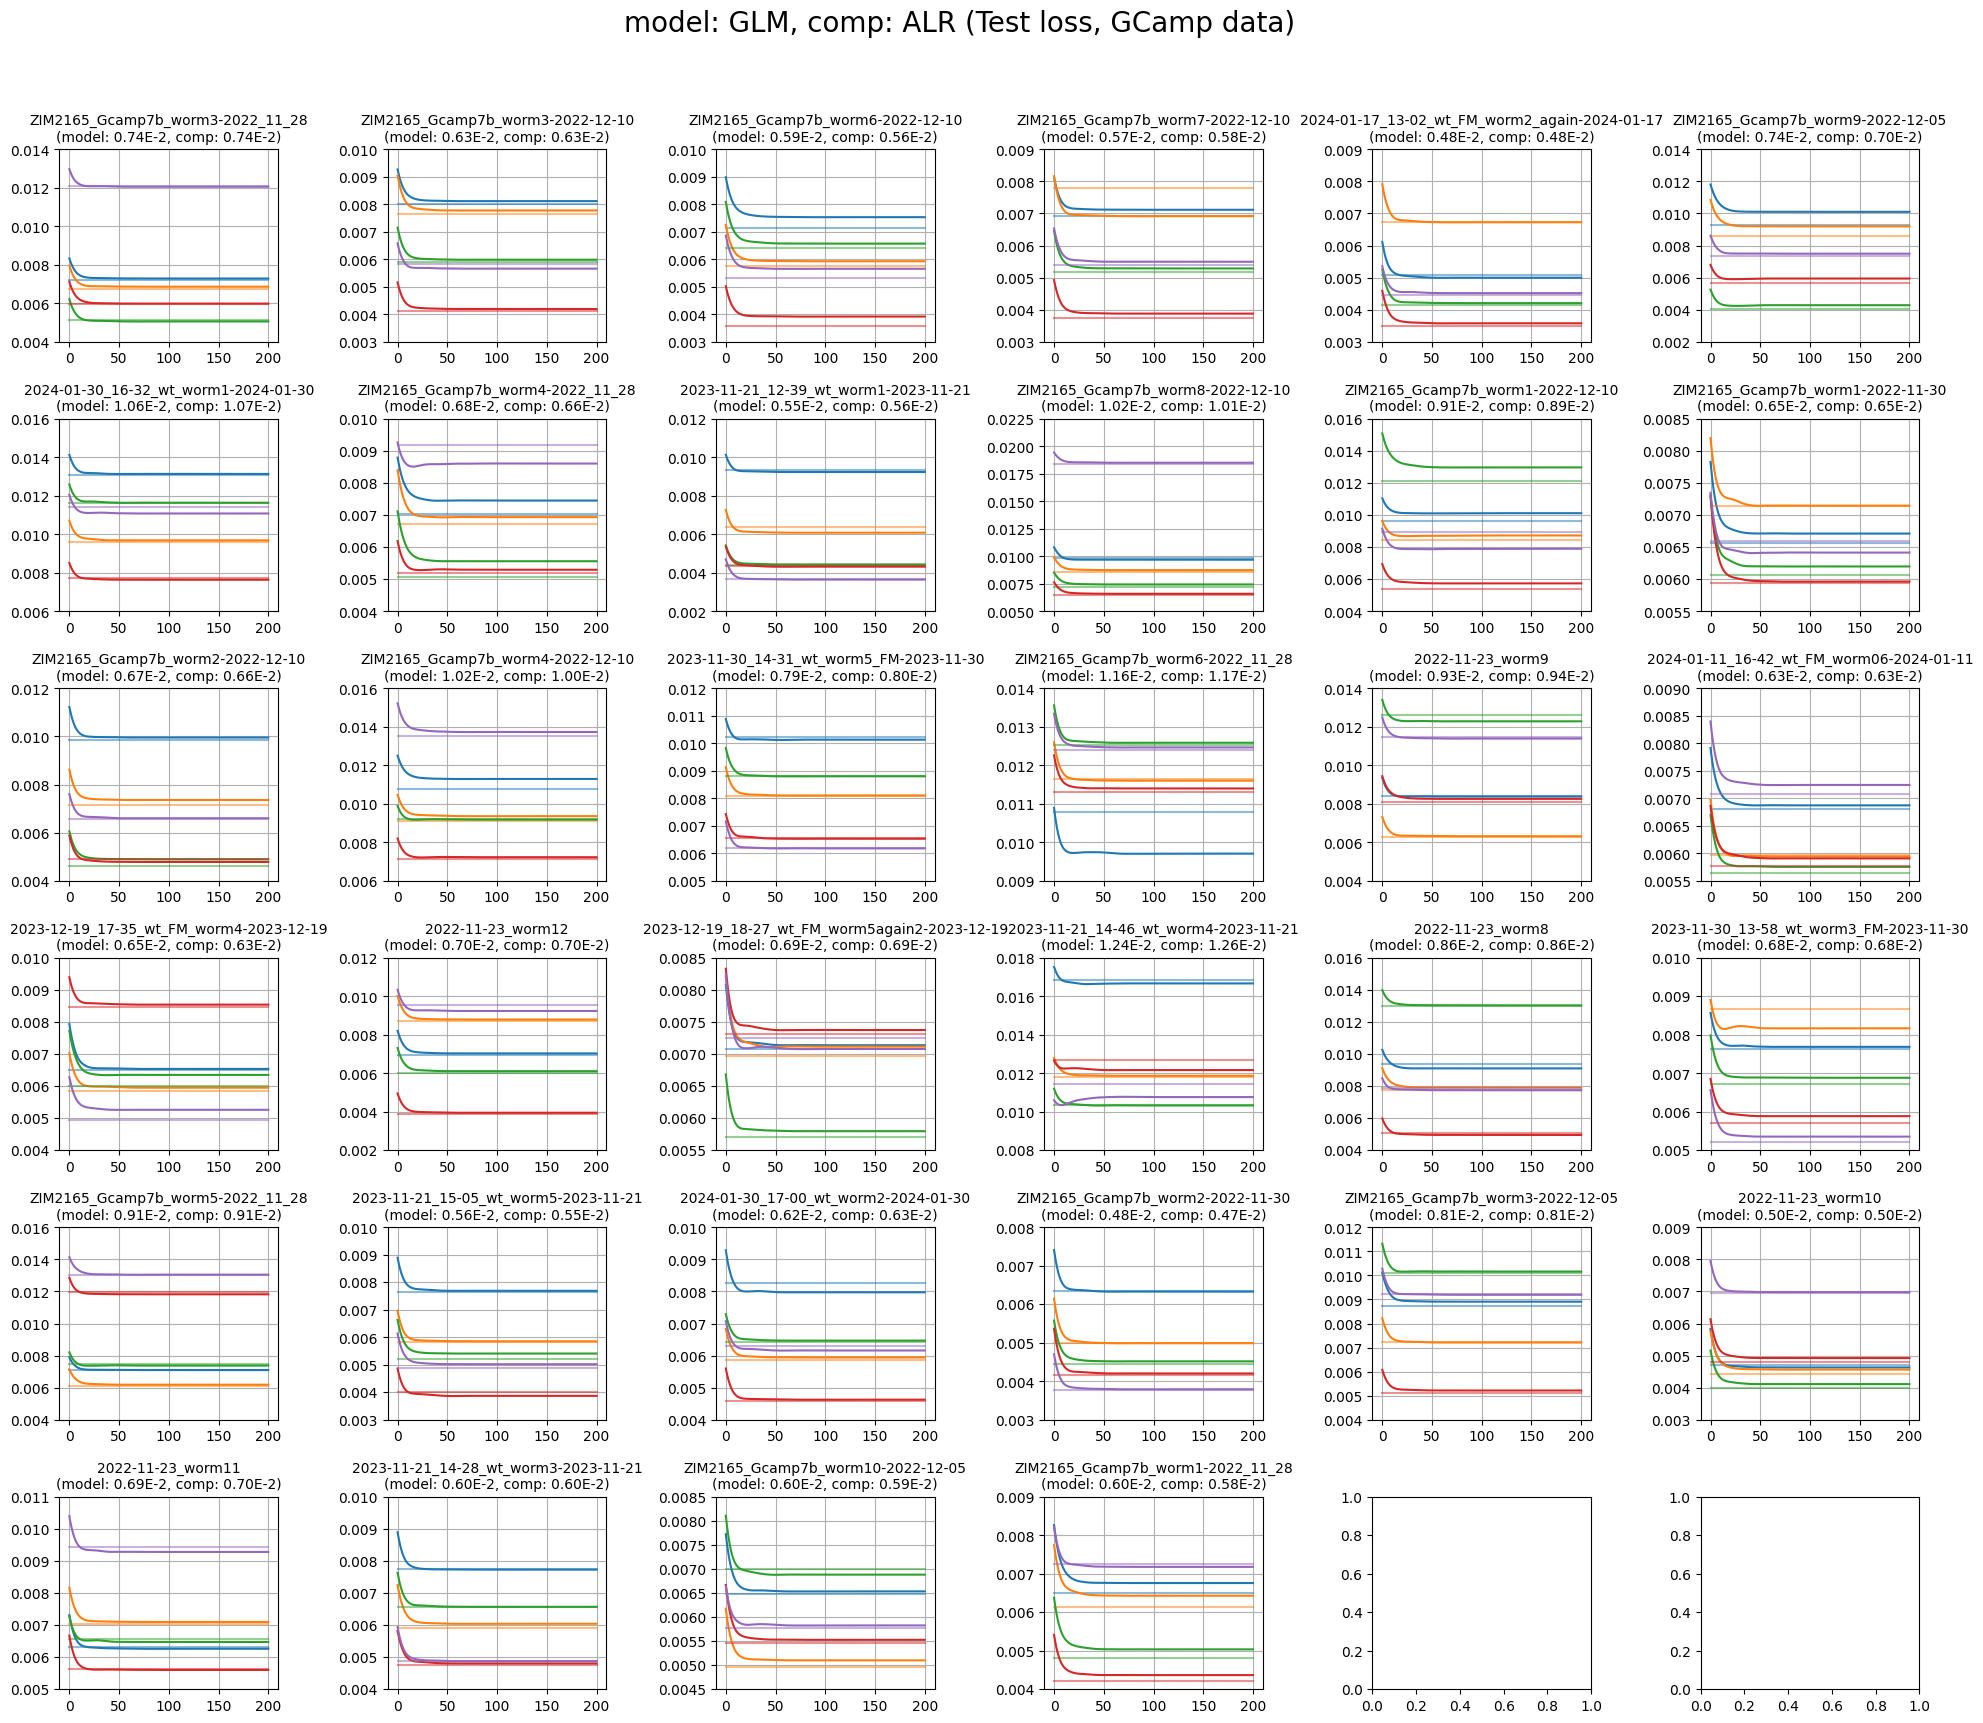

In [21]:
plot_utils.plot_losses(filenames, glm_models_losses, [loss[:, None] * np.ones((1, glm_models_losses[0].shape[1])) for loss in alr_models_losses], 'model: GLM, comp: ALR (Test loss, GCamp data)')

### HGM

In [22]:
hgm_models_scores = list()
hgm_models_losses = list()
hgm_models_losses_tr = list()
# hgm_models_params = list()
__hgm_models_grads = list()

for i in range(len(filenames)):
	print(f'{i + 1}/{len(filenames)}: {filenames[i]}  ', end='')

	splits = list(StratifiedKFold(n_splits=5).split(np.zeros(eigenworms[i].values.shape[0]), discrete_states[i]['REV'].values))

	neuron_scores_per_split, losses_per_split, losses_tr_per_split, __grads_per_split = train_numerical_model(hgm, splits,
																											  np.array(eigenworms[i].values),
																											  jnp.array(traces_residual[i].values),
																											  jnp.array(modes_manifold[i].values))

	hgm_models_scores.append(neuron_scores_per_split)
	hgm_models_losses.append(losses_per_split)
	hgm_models_losses_tr.append(losses_tr_per_split)
	__hgm_models_grads.append(__grads_per_split)

1/34: ZIM2165_Gcamp7b_worm3-2022_11_28_no_image_data  2/34: ZIM2165_Gcamp7b_worm3-2022-12-10_no_image_data  3/34: ZIM2165_Gcamp7b_worm6-2022-12-10_no_image_data  4/34: ZIM2165_Gcamp7b_worm7-2022-12-10_no_image_data  5/34: 2024-01-17_13-02_wt_FM_worm2_again-2024-01-17_no_image_data  6/34: ZIM2165_Gcamp7b_worm9-2022-12-05_no_image_data  7/34: 2024-01-30_16-32_wt_worm1-2024-01-30_no_image_data  8/34: ZIM2165_Gcamp7b_worm4-2022_11_28_no_image_data  9/34: 2023-11-21_12-39_wt_worm1-2023-11-21_no_image_data  10/34: ZIM2165_Gcamp7b_worm8-2022-12-10_no_image_data  11/34: ZIM2165_Gcamp7b_worm1-2022-12-10_no_image_data  12/34: ZIM2165_Gcamp7b_worm1-2022-11-30_no_image_data  13/34: ZIM2165_Gcamp7b_worm2-2022-12-10_no_image_data  14/34: ZIM2165_Gcamp7b_worm4-2022-12-10_no_image_data  15/34: 2023-11-30_14-31_wt_worm5_FM-2023-11-30_no_image_data  16/34: ZIM2165_Gcamp7b_worm6-2022_11_28_no_image_data  17/34: 2022-11-23_worm9_no_image_data  18/34: 2024-01-11_16-42_wt_FM_worm06-2024-01-11_no_image_data 

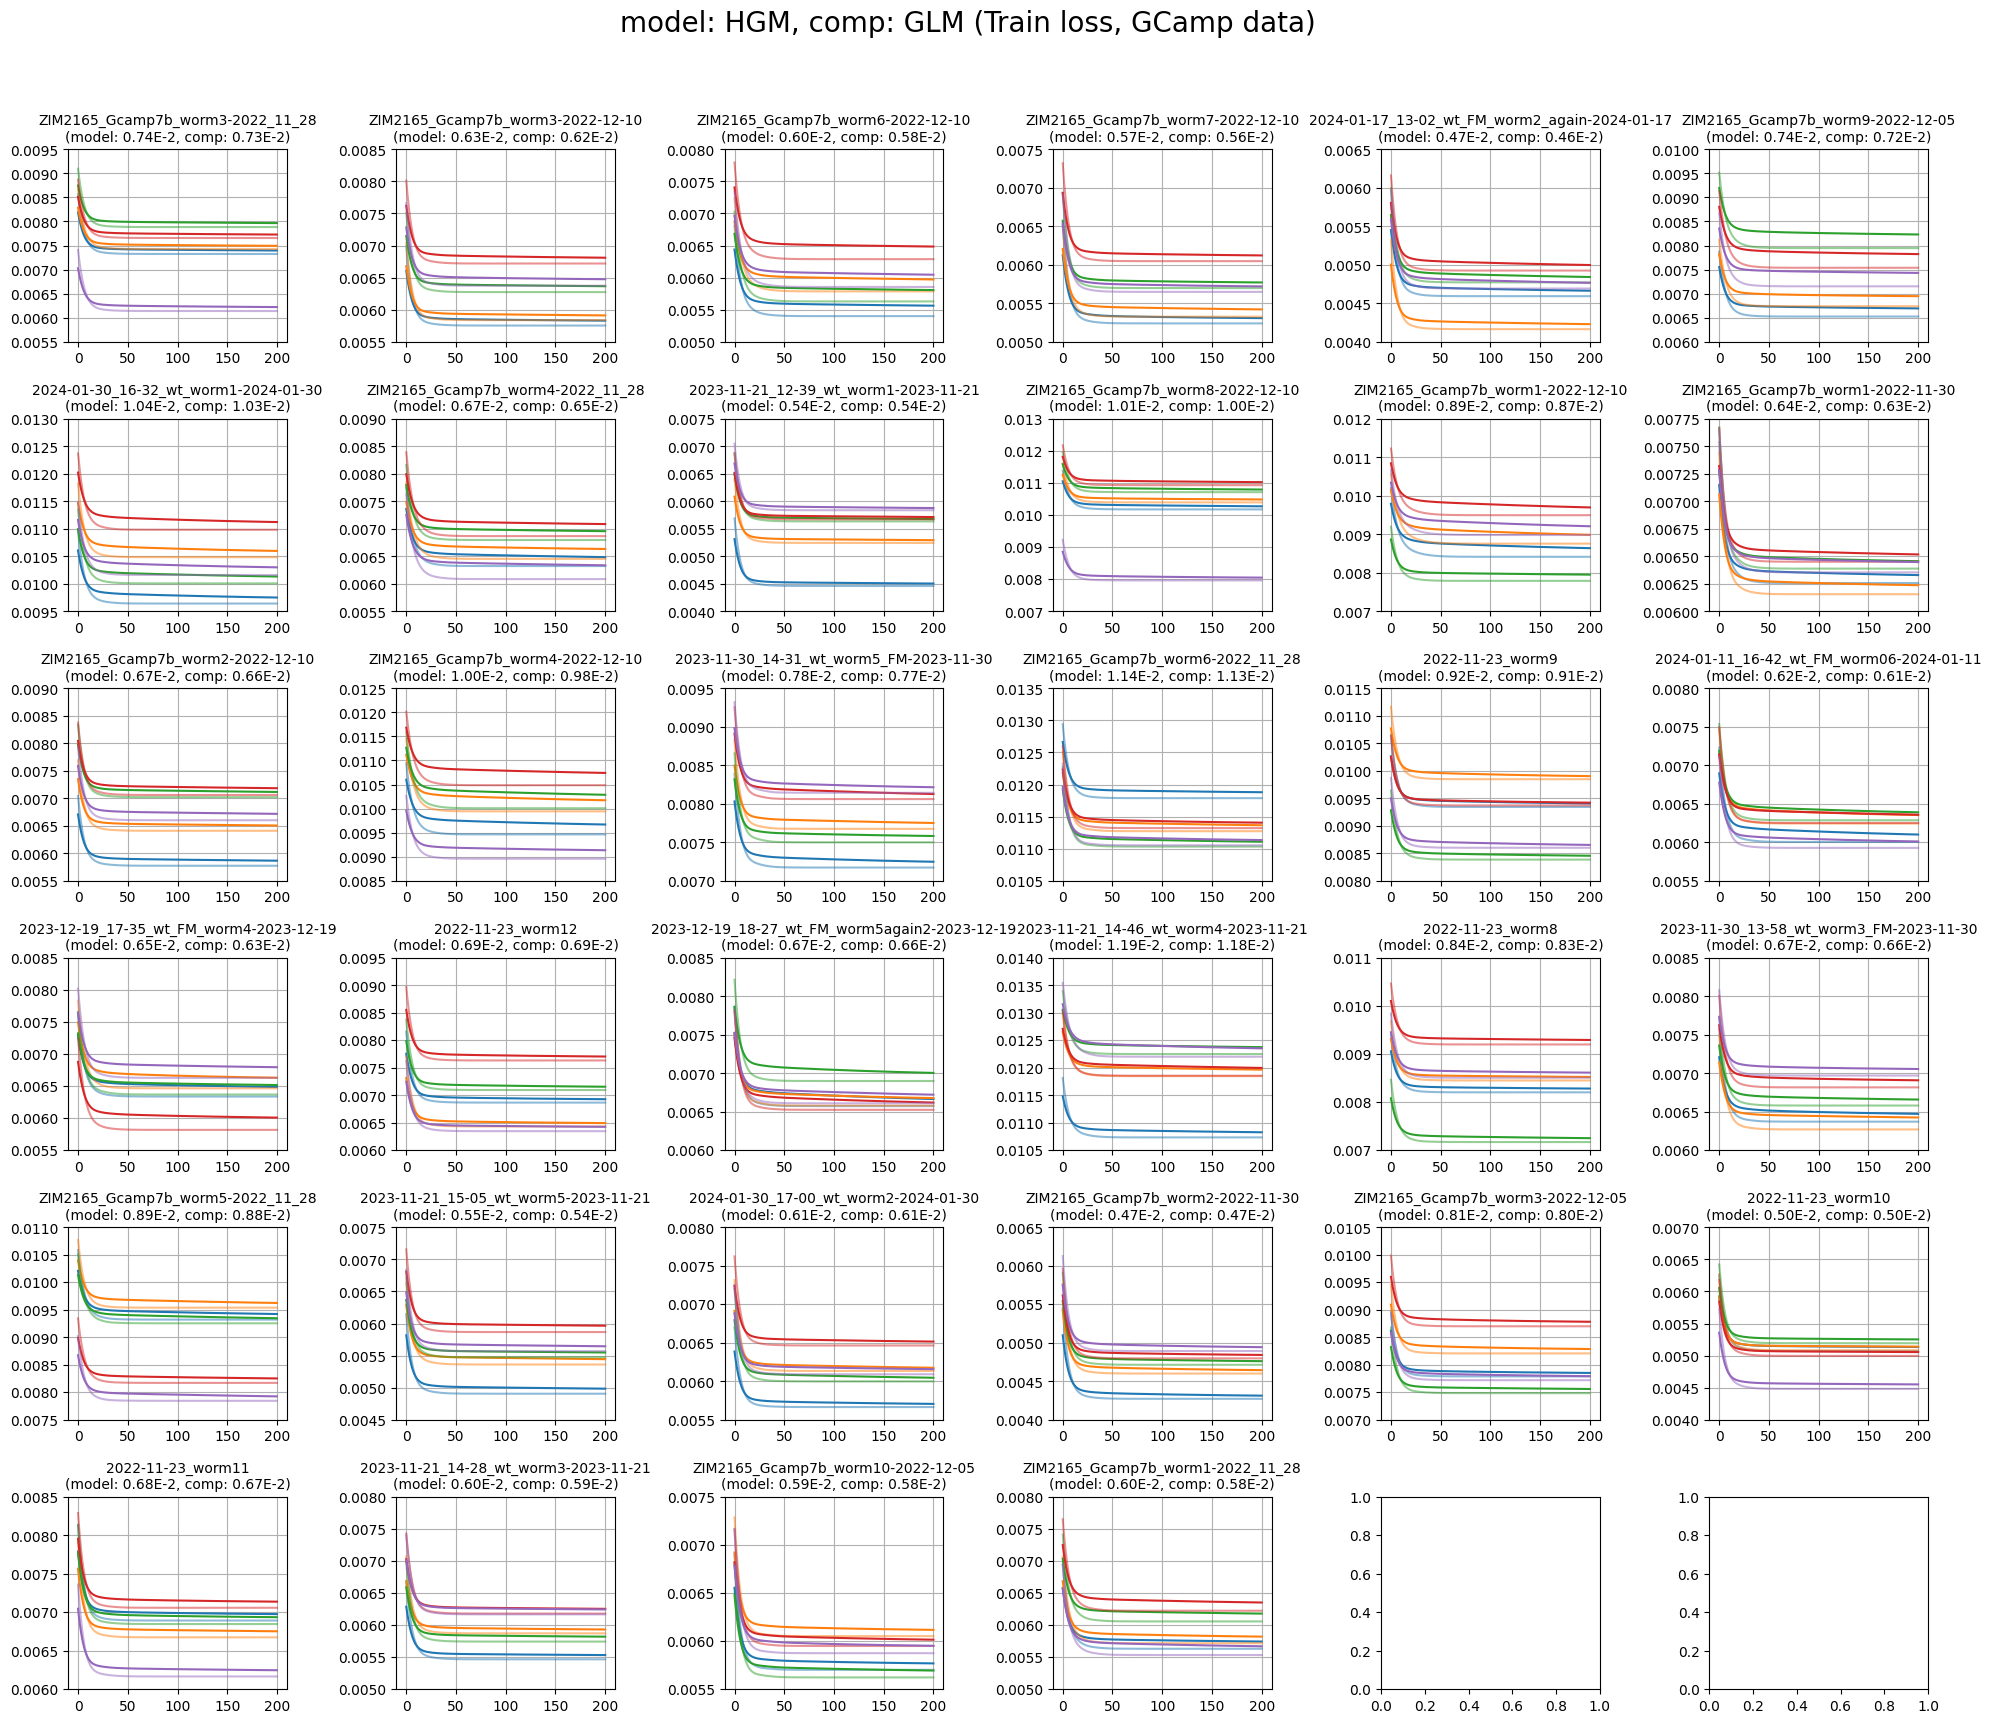

In [23]:
plot_utils.plot_losses(filenames, hgm_models_losses_tr, glm_models_losses_tr, 'model: HGM, comp: GLM (Train loss, GCamp data)')

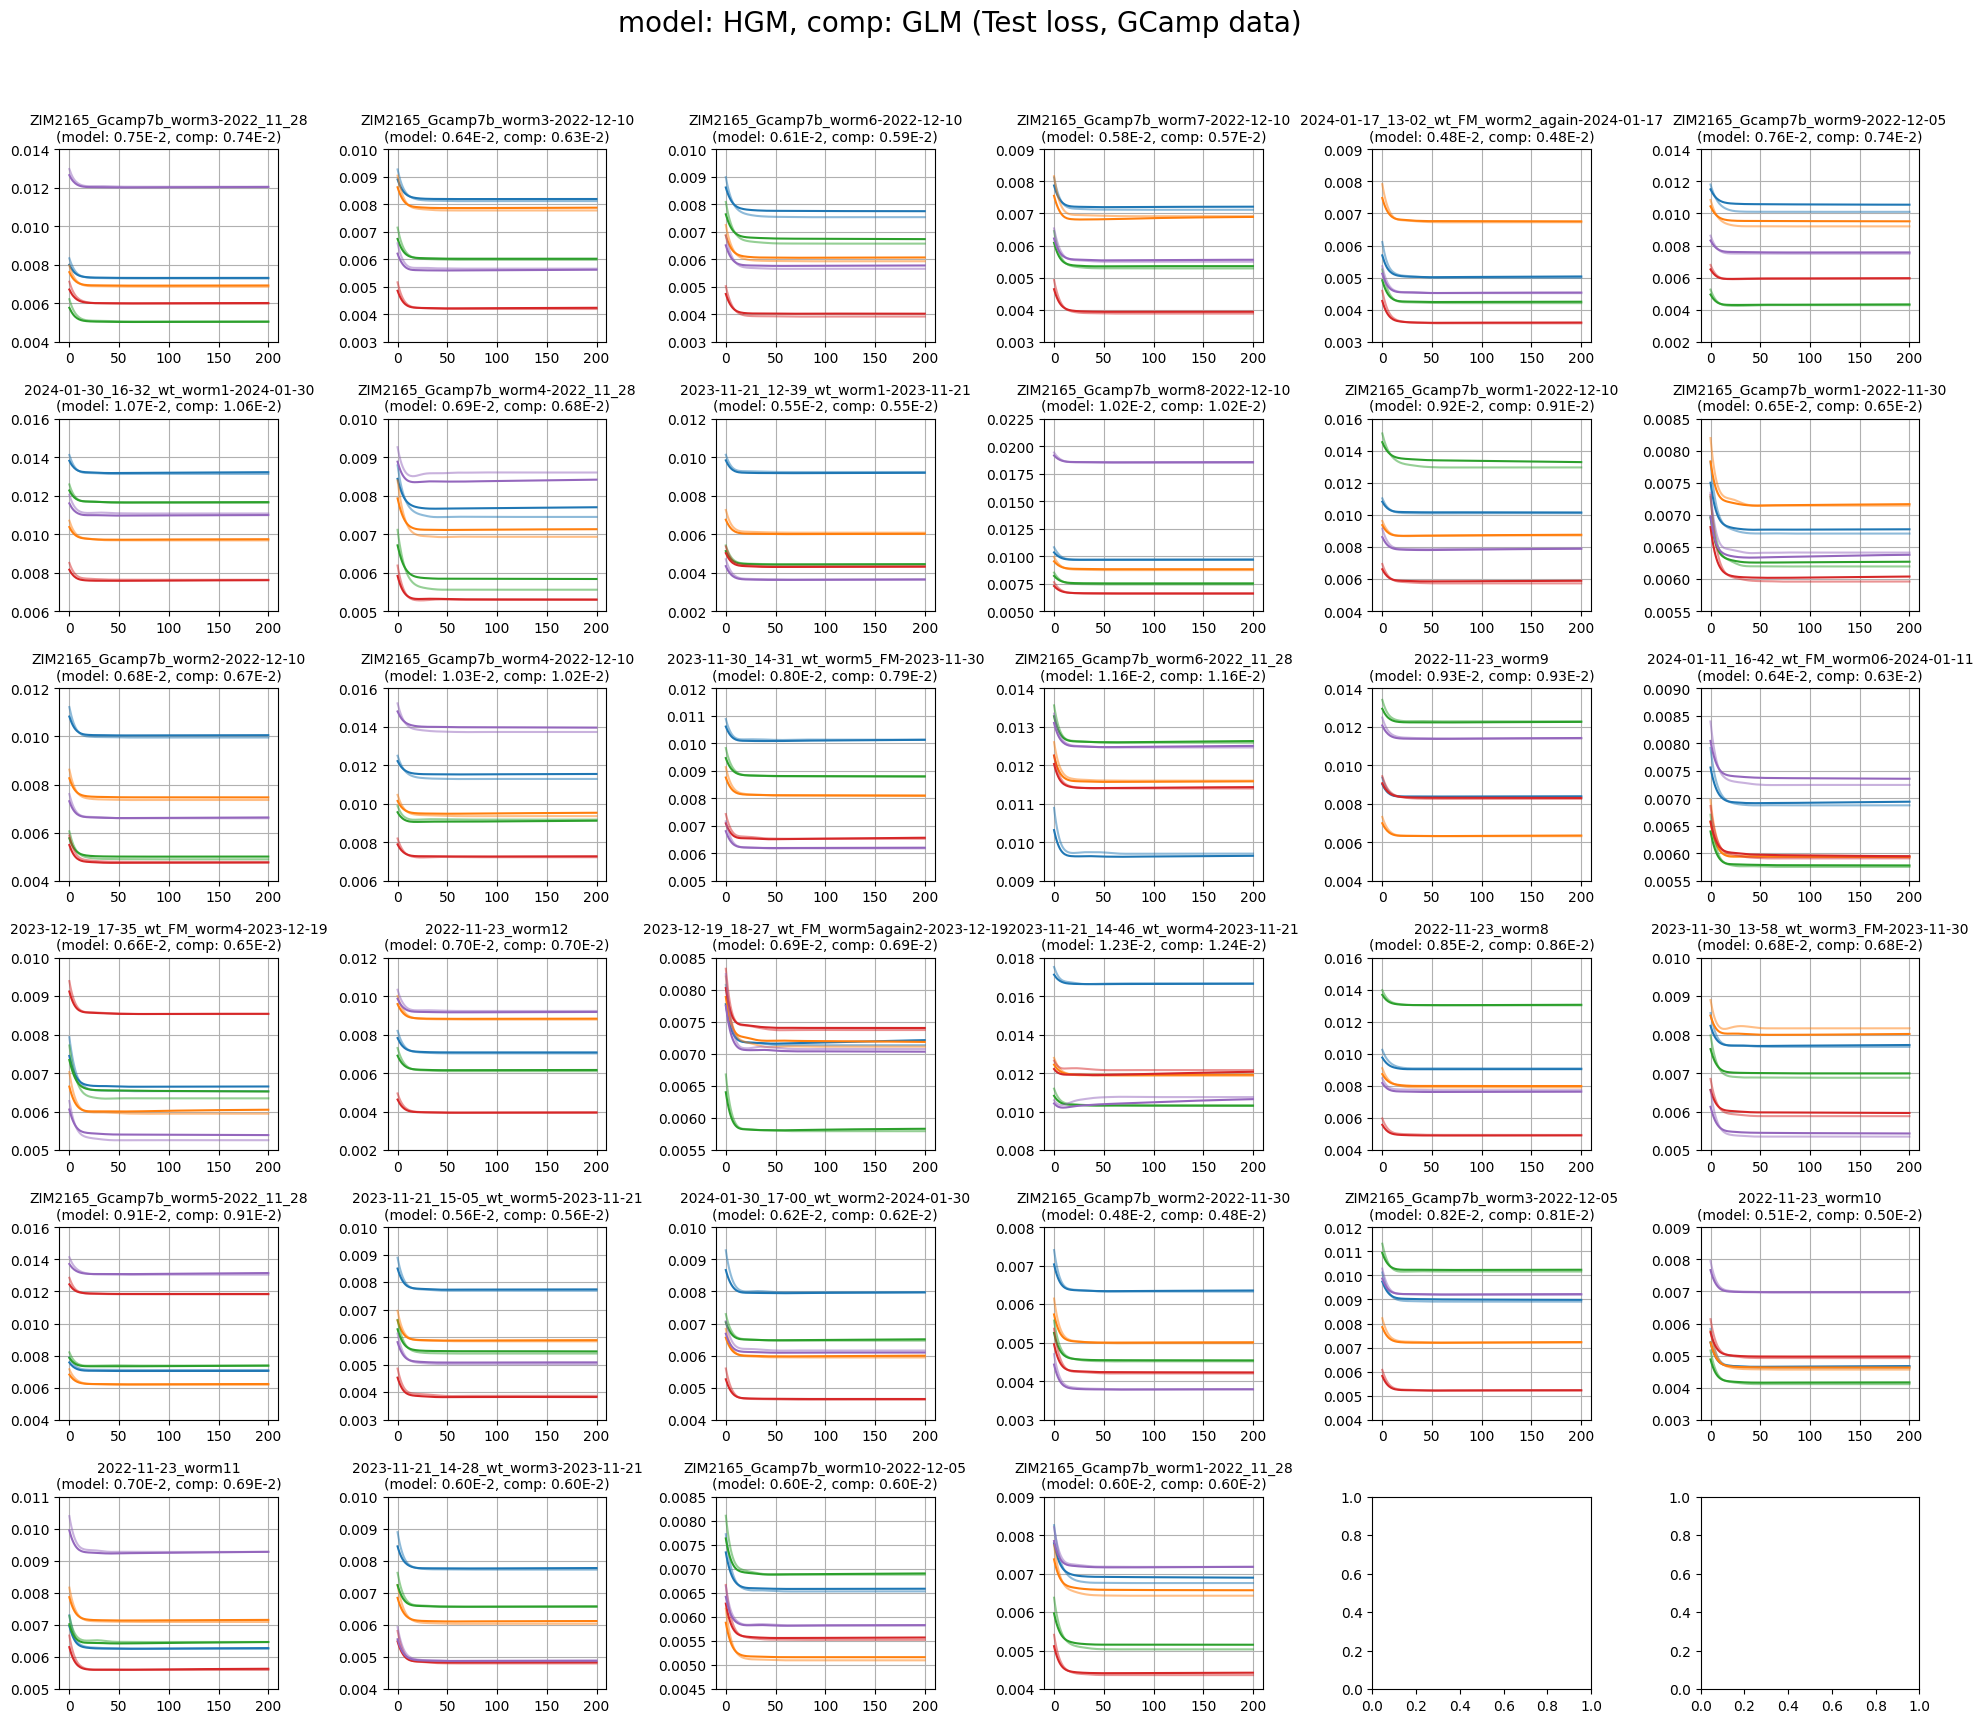

In [24]:
plot_utils.plot_losses(filenames, hgm_models_losses, glm_models_losses, 'model: HGM, comp: GLM (Test loss, GCamp data)')

### __loss gradient per weights over time

In [25]:
# fig, axes = plt.subplots(1, 2, figsize=(12, 3))
# for ax in axes:
#     ax.set_ylim(-0.005, 0.004)
#
# for i in range(1):
# 	gradsW = np.array([val['W'] for val in __glm_models_grads[-1][i]])
#
# 	gradsW1 = np.array([val['W1'] for val in __hgm_models_grads[-1][i]])
# 	gradsW2 = np.array([val['W2'] for val in __hgm_models_grads[-1][i]])
#
#
# 	axes[0].plot(np.mean(gradsW, axis=1))
#
# 	axes[1].plot(np.mean(gradsW1, axis=1))
# 	# axes[1].plot(np.mean(gradsW2, axis=1))

# GFP

### manifold

In [26]:
selection = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']

(modes_manifold_gfp,
 traces_manifold_gfp,
 cca_loadings_man_gfp,
 vars_expl_man_gfp,
 vars_expl_man_rs_gfp) = train_utils.get_manifolds(traces_gfp,
												   [ds[selection] for ds in discrete_states_gfp],
												   n_cc=2, n_pc=5)

# plot_utils.plot_manifolds(filenames_gfp, modes_manifold_gfp, vars_expl_man_gfp, vars_expl_man_rs_gfp)

In [27]:
traces_residual_gfp = [pd.DataFrame(data=trace.values - trace_manifold.values, columns=trace.columns) for trace, trace_manifold in zip(traces_gfp, traces_manifold_gfp)]

### analytical linear regression

In [28]:
alr_models_scores_gfp = list()
alr_models_losses_gfp = list()
alr_models_losses_tr_gfp = list()
for i in range(len(filenames_gfp)):
	print(f'{i+1}/{len(filenames_gfp)}: {filenames_gfp[i]} ', end='')

	splits = list(StratifiedKFold(n_splits=5).split(np.zeros(eigenworms_gfp[i].values.shape[0]), discrete_states_gfp[i]['REV'].values))

	score_per_split, loss_per_split, loss_tr_per_split = fit_analytical_model(splits, eigenworms_gfp[i].values, traces_residual_gfp[i].values)

	alr_models_scores_gfp.append(score_per_split)
	alr_models_losses_gfp.append(loss_per_split)
	alr_models_losses_tr_gfp.append(loss_tr_per_split)

1/8: ZIM2319_GFP_worm3-2022-12-10_no_image_data 2/8: ZIM2319_GFP_worm1-2022-12-10_no_image_data 3/8: ZIM2319_GFP_worm2-2022-12-10_no_image_data 4/8: ZIM2319_GFP_worm6-2022-12-10_no_image_data 5/8: ZIM2319_GFP_worm8-2022-12-10_no_image_data 6/8: ZIM2319_GFP_worm4-2022-12-10_no_image_data 7/8: ZIM2319_GFP_worm7-2022-12-10_no_image_data 8/8: ZIM2319_GFP_worm5-2022-12-10_no_image_data 

### GLM

In [29]:
glm_models_scores_gfp = list()
glm_models_losses_gfp = list()
glm_models_losses_tr_gfp = list()
# glm_models_params_gfp = list()

for i in range(len(filenames_gfp)):
	print(f'{i + 1}/{len(filenames_gfp)}: {filenames_gfp[i]}  ', end='')

	splits = list(StratifiedKFold(n_splits=5).split(np.zeros(eigenworms_gfp[i].values.shape[0]), discrete_states_gfp[i]['REV'].values))

	neuron_scores_per_split, losses_per_split, losses_tr_per_split, __ = train_numerical_model(glm, splits,
																							   jnp.array(eigenworms_gfp[i].values),
																							   jnp.array(traces_residual_gfp[i].values),
																							   None)

	glm_models_scores_gfp.append(neuron_scores_per_split)
	glm_models_losses_gfp.append(losses_per_split)
	glm_models_losses_tr_gfp.append(losses_tr_per_split)

1/8: ZIM2319_GFP_worm3-2022-12-10_no_image_data  2/8: ZIM2319_GFP_worm1-2022-12-10_no_image_data  3/8: ZIM2319_GFP_worm2-2022-12-10_no_image_data  4/8: ZIM2319_GFP_worm6-2022-12-10_no_image_data  5/8: ZIM2319_GFP_worm8-2022-12-10_no_image_data  6/8: ZIM2319_GFP_worm4-2022-12-10_no_image_data  7/8: ZIM2319_GFP_worm7-2022-12-10_no_image_data  8/8: ZIM2319_GFP_worm5-2022-12-10_no_image_data  

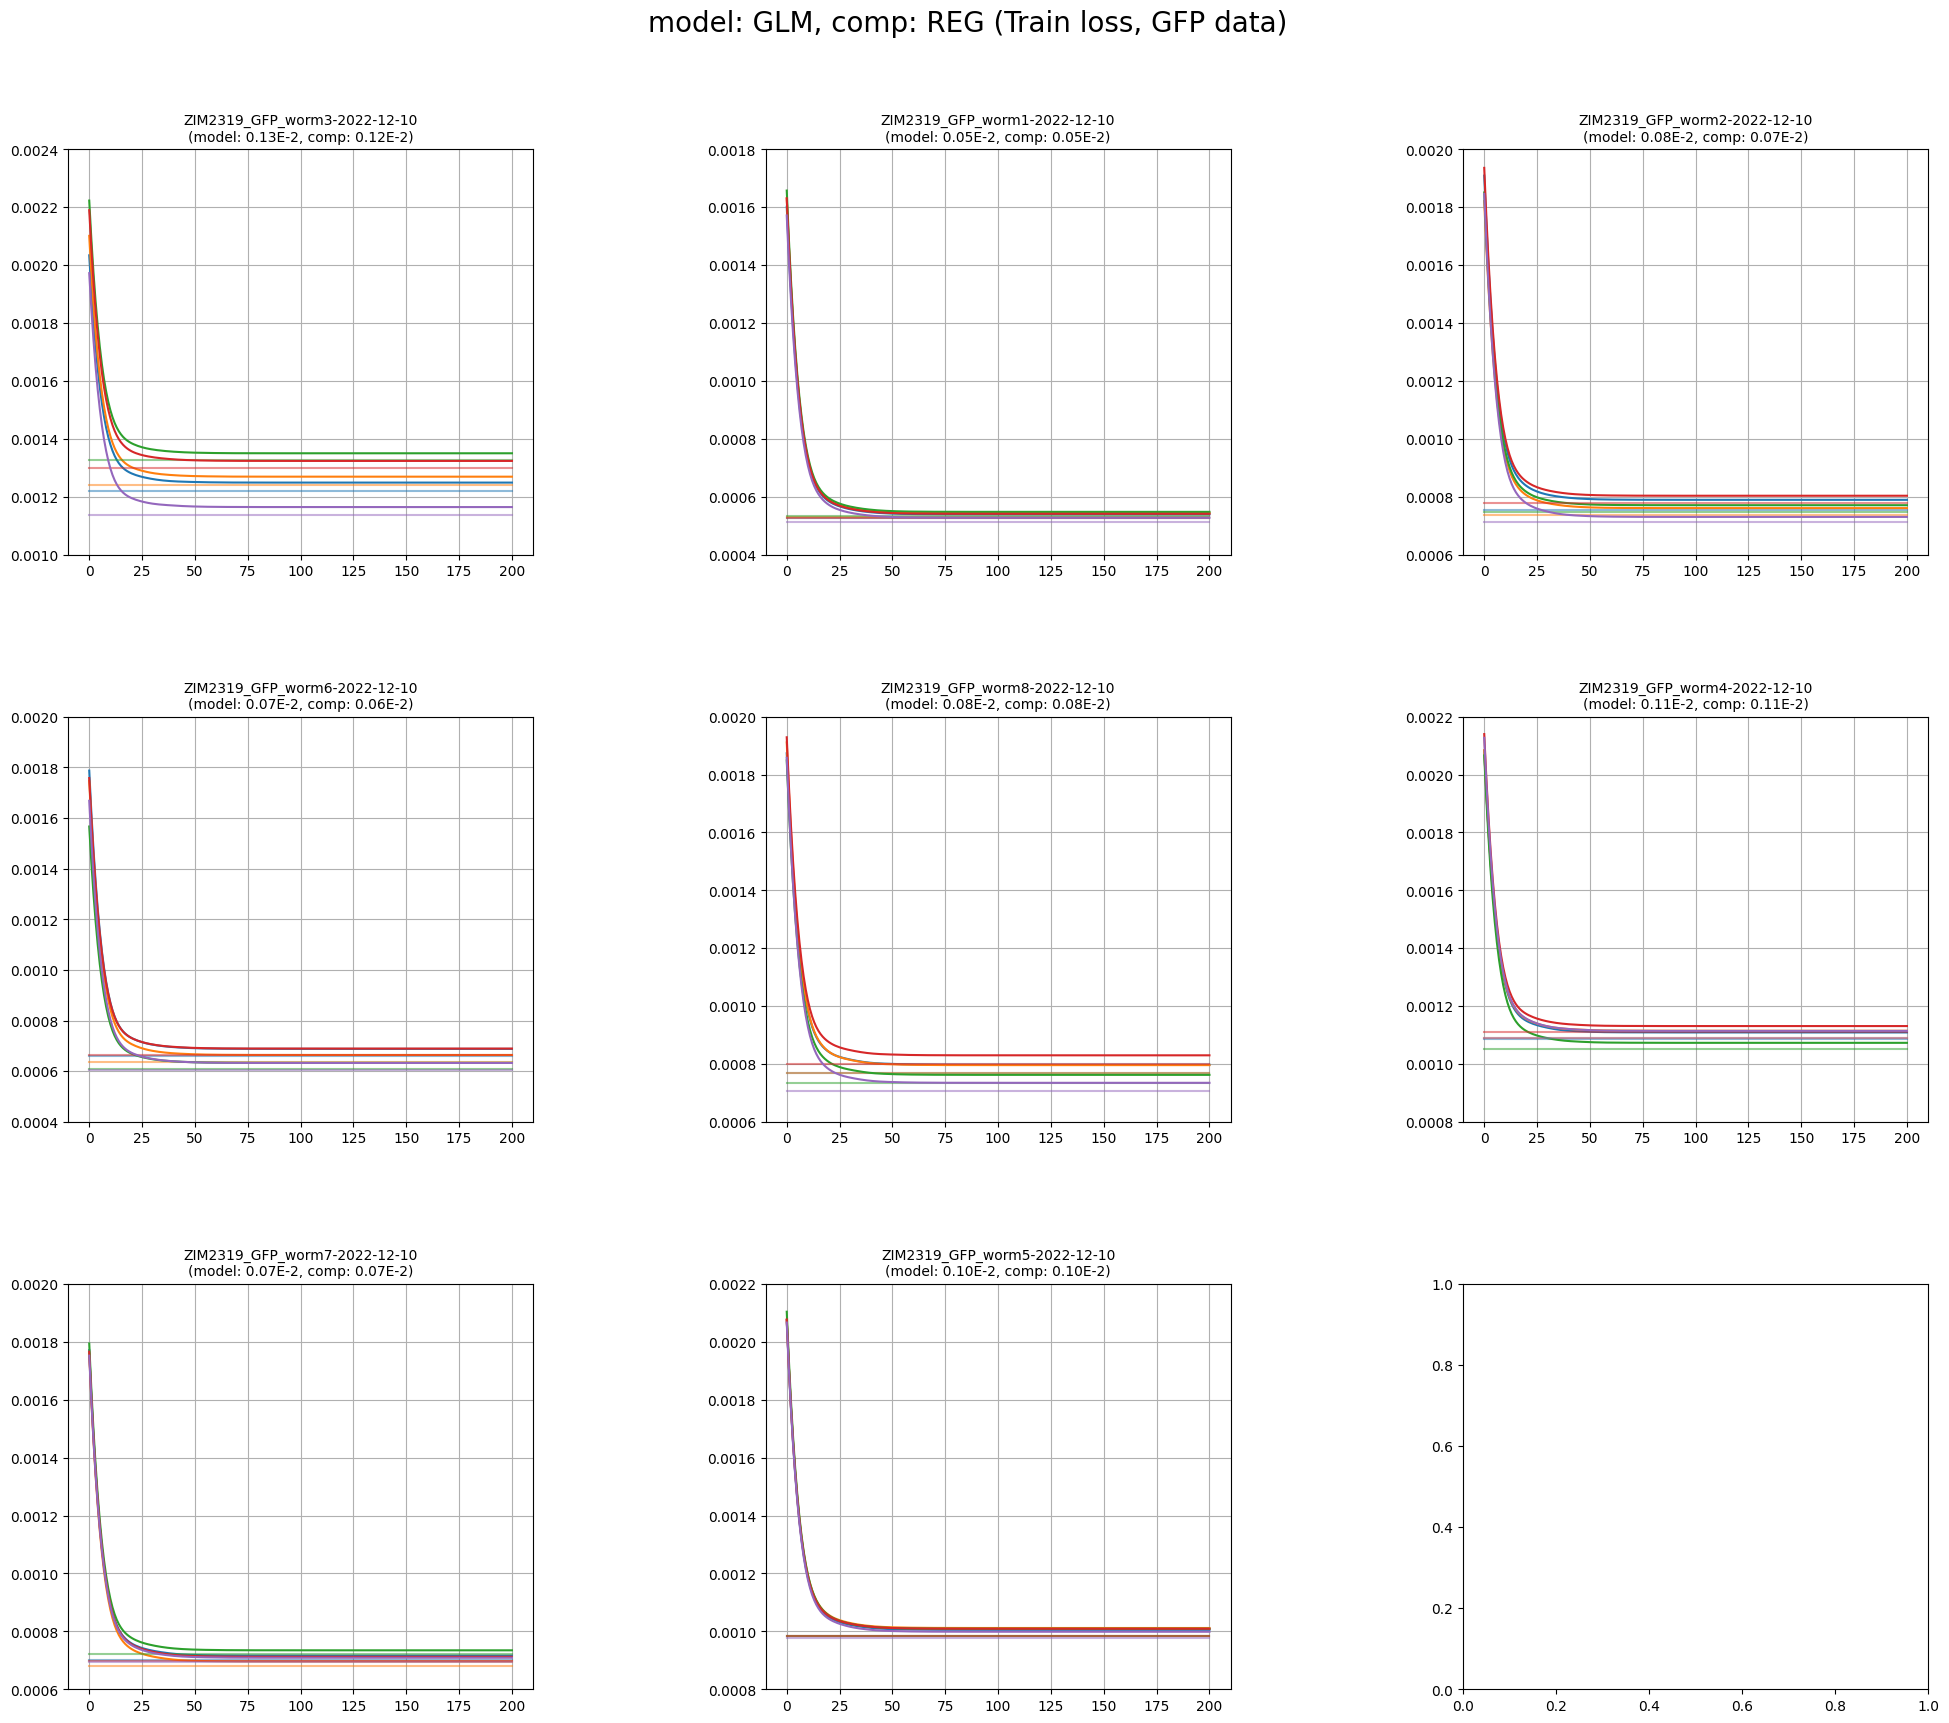

In [30]:
plot_utils.plot_losses(filenames_gfp, glm_models_losses_tr_gfp, [loss[:, None] * np.ones((1, glm_models_losses_tr_gfp[0].shape[1])) for loss in alr_models_losses_tr_gfp], 'model: GLM, comp: REG (Train loss, GFP data)')

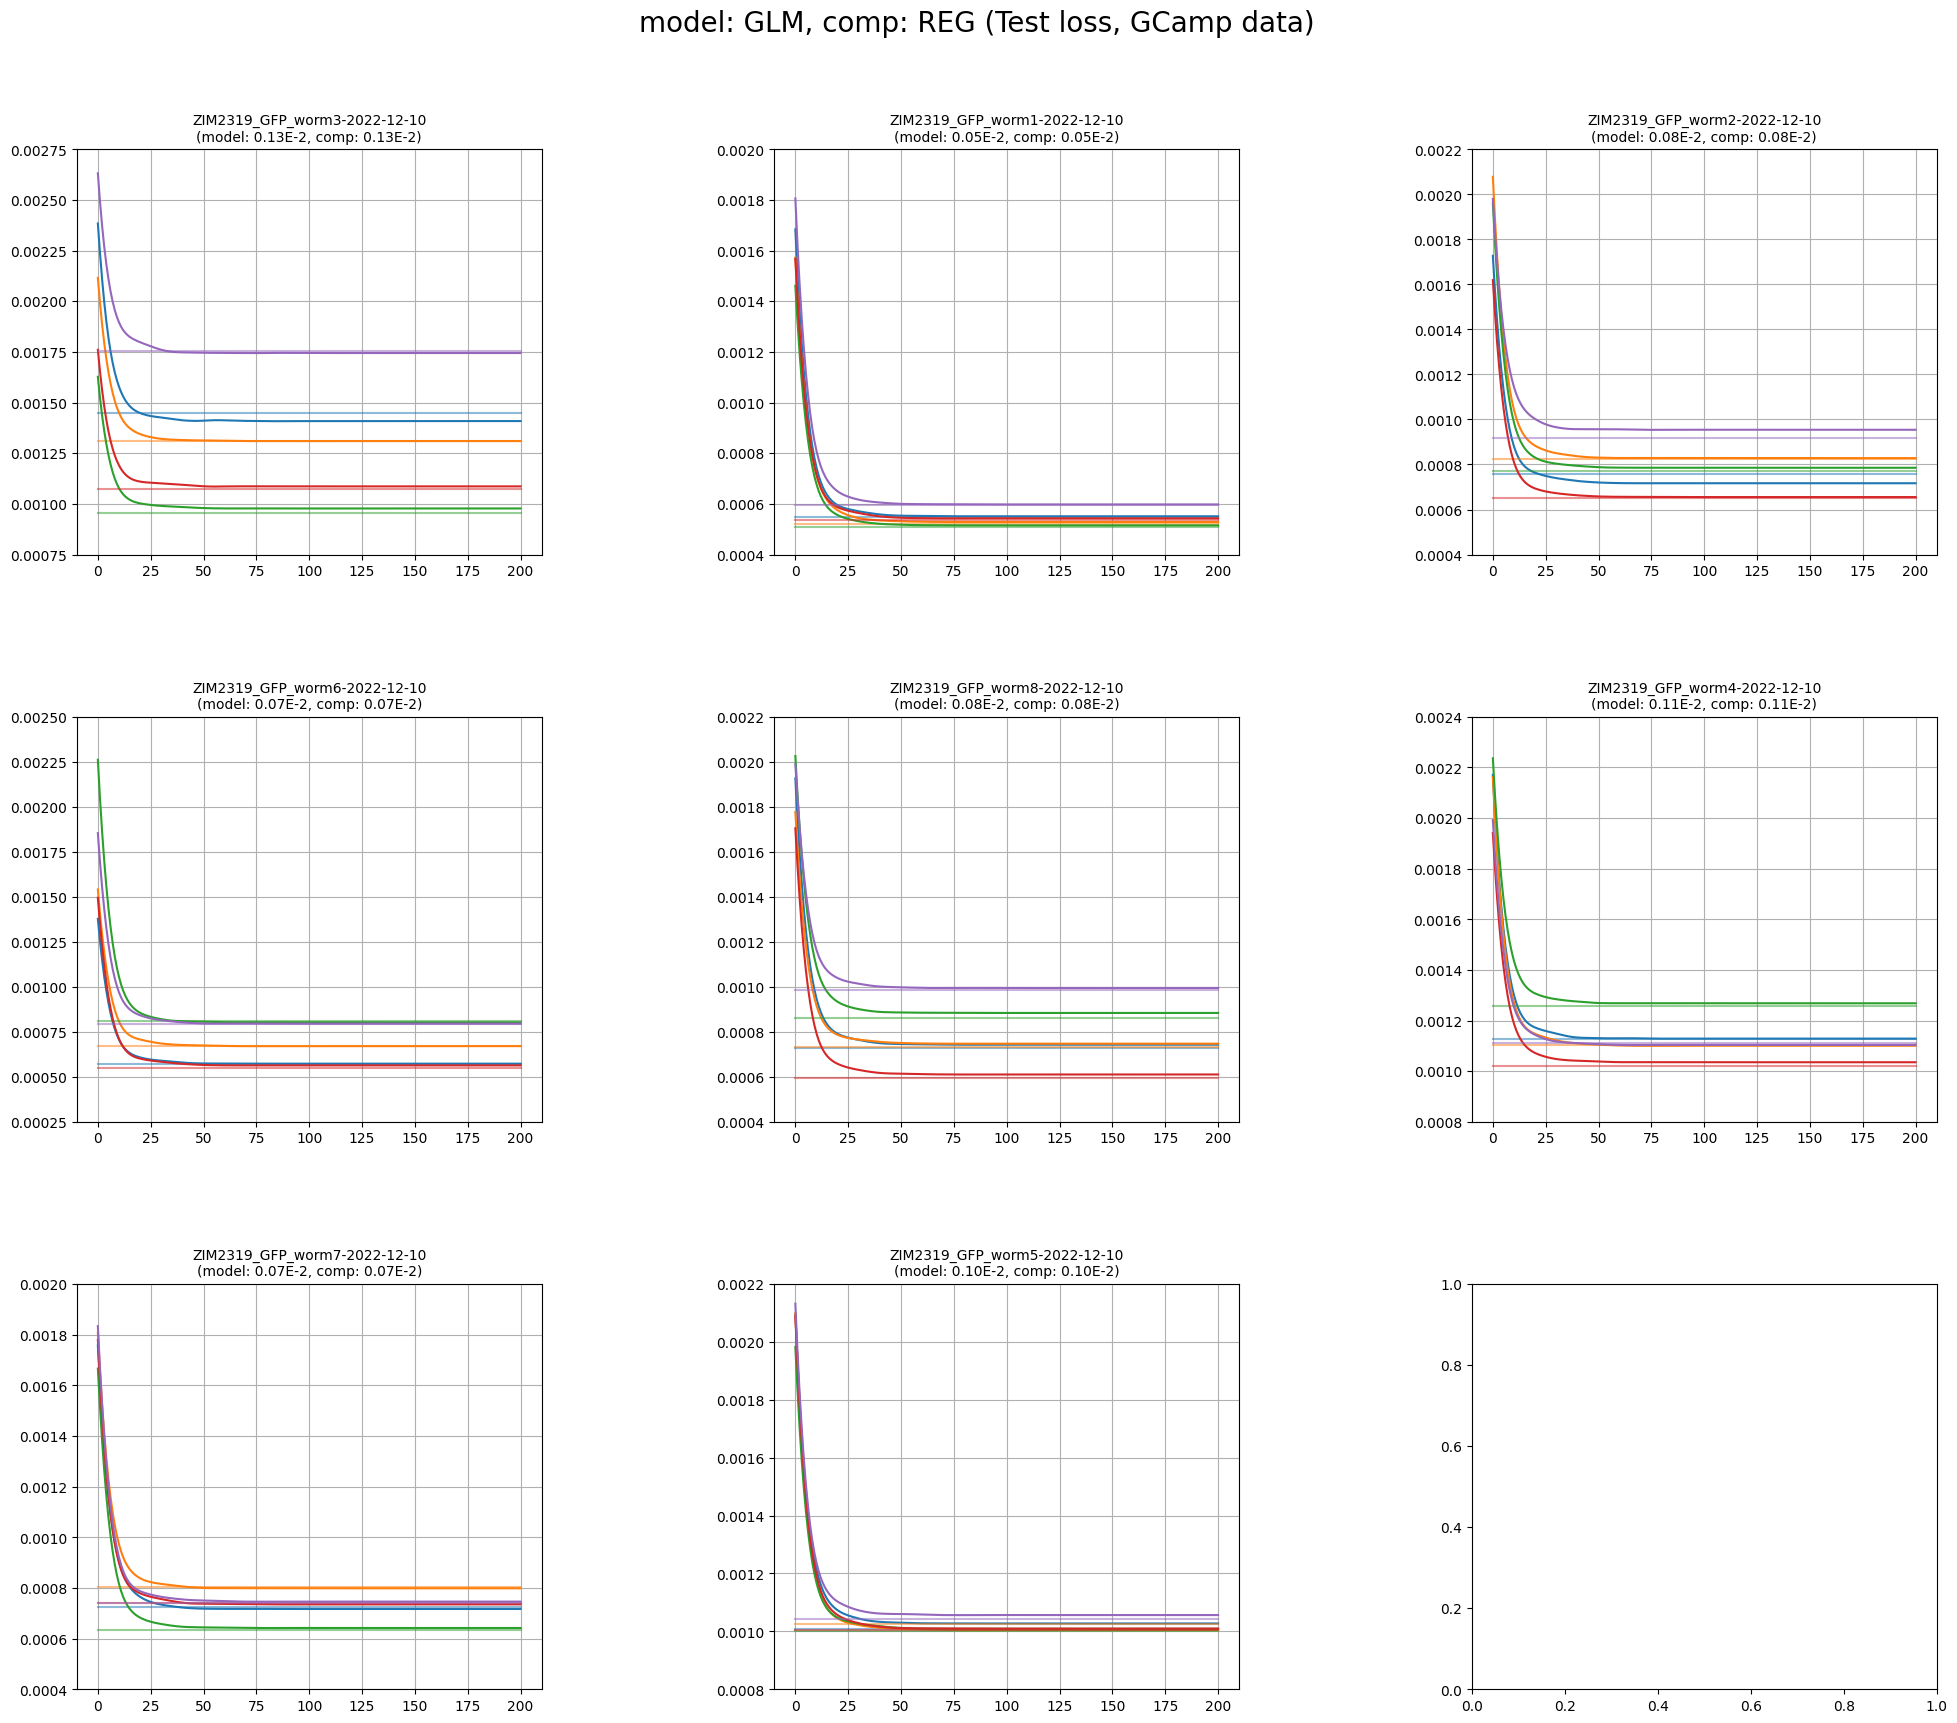

In [31]:
plot_utils.plot_losses(filenames_gfp, glm_models_losses_gfp, [loss[:, None] * np.ones((1, glm_models_losses_gfp[0].shape[1])) for loss in alr_models_losses_gfp], 'model: GLM, comp: REG (Test loss, GCamp data)')

### HGM

In [32]:
hgm_models_scores_gfp = list()
hgm_models_losses_gfp = list()
hgm_models_losses_tr_gfp = list()
# hgm_models_params_gfp = list()

for i in range(len(filenames_gfp)):
	print(f'{i + 1}/{len(filenames_gfp)}: {filenames_gfp[i]}  ', end='')

	splits = list(StratifiedKFold(n_splits=5).split(np.zeros(eigenworms_gfp[i].shape[0]), discrete_states_gfp[i]['REV'].values))

	neuron_scores_per_split, losses_per_split, losses_tr_per_split, __ = train_numerical_model(hgm, splits,
																							   jnp.array(eigenworms_gfp[i].values),
																							   jnp.array(traces_residual_gfp[i].values),
																							   jnp.array(modes_manifold_gfp[i].values))

	hgm_models_scores_gfp.append(neuron_scores_per_split)
	hgm_models_losses_gfp.append(losses_per_split)
	hgm_models_losses_tr_gfp.append(losses_tr_per_split)

1/8: ZIM2319_GFP_worm3-2022-12-10_no_image_data  2/8: ZIM2319_GFP_worm1-2022-12-10_no_image_data  3/8: ZIM2319_GFP_worm2-2022-12-10_no_image_data  4/8: ZIM2319_GFP_worm6-2022-12-10_no_image_data  5/8: ZIM2319_GFP_worm8-2022-12-10_no_image_data  6/8: ZIM2319_GFP_worm4-2022-12-10_no_image_data  7/8: ZIM2319_GFP_worm7-2022-12-10_no_image_data  8/8: ZIM2319_GFP_worm5-2022-12-10_no_image_data  

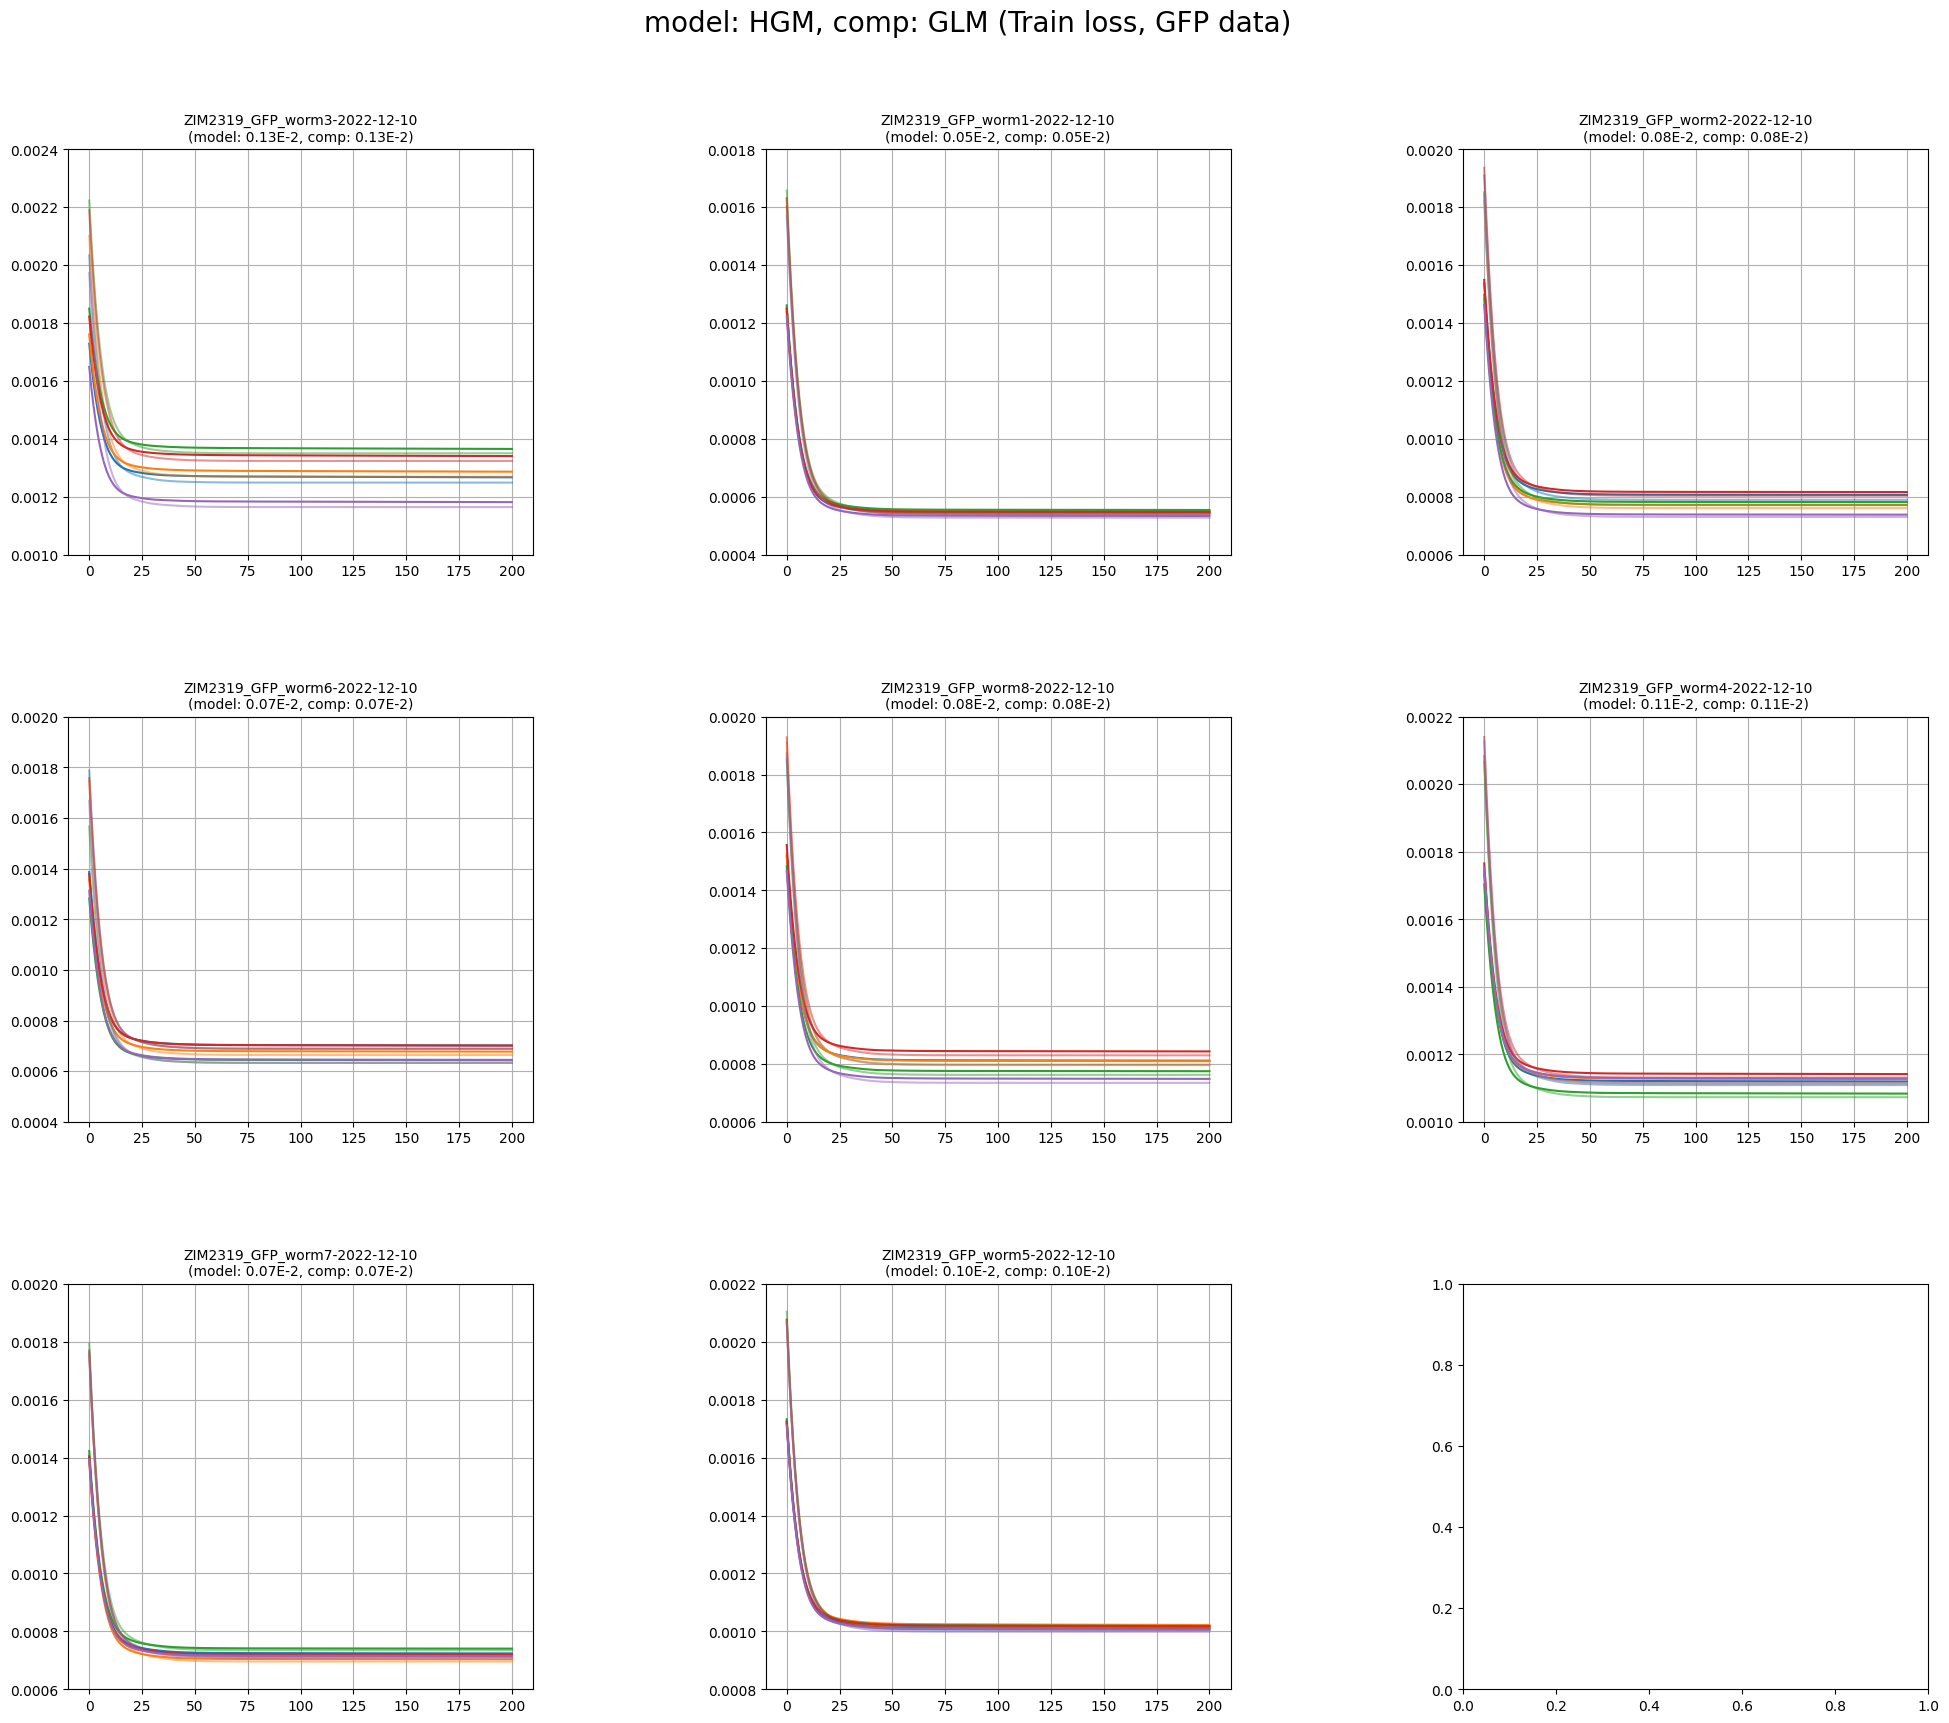

In [33]:
plot_utils.plot_losses(filenames_gfp, hgm_models_losses_tr_gfp, glm_models_losses_tr_gfp, 'model: HGM, comp: GLM (Train loss, GFP data)')

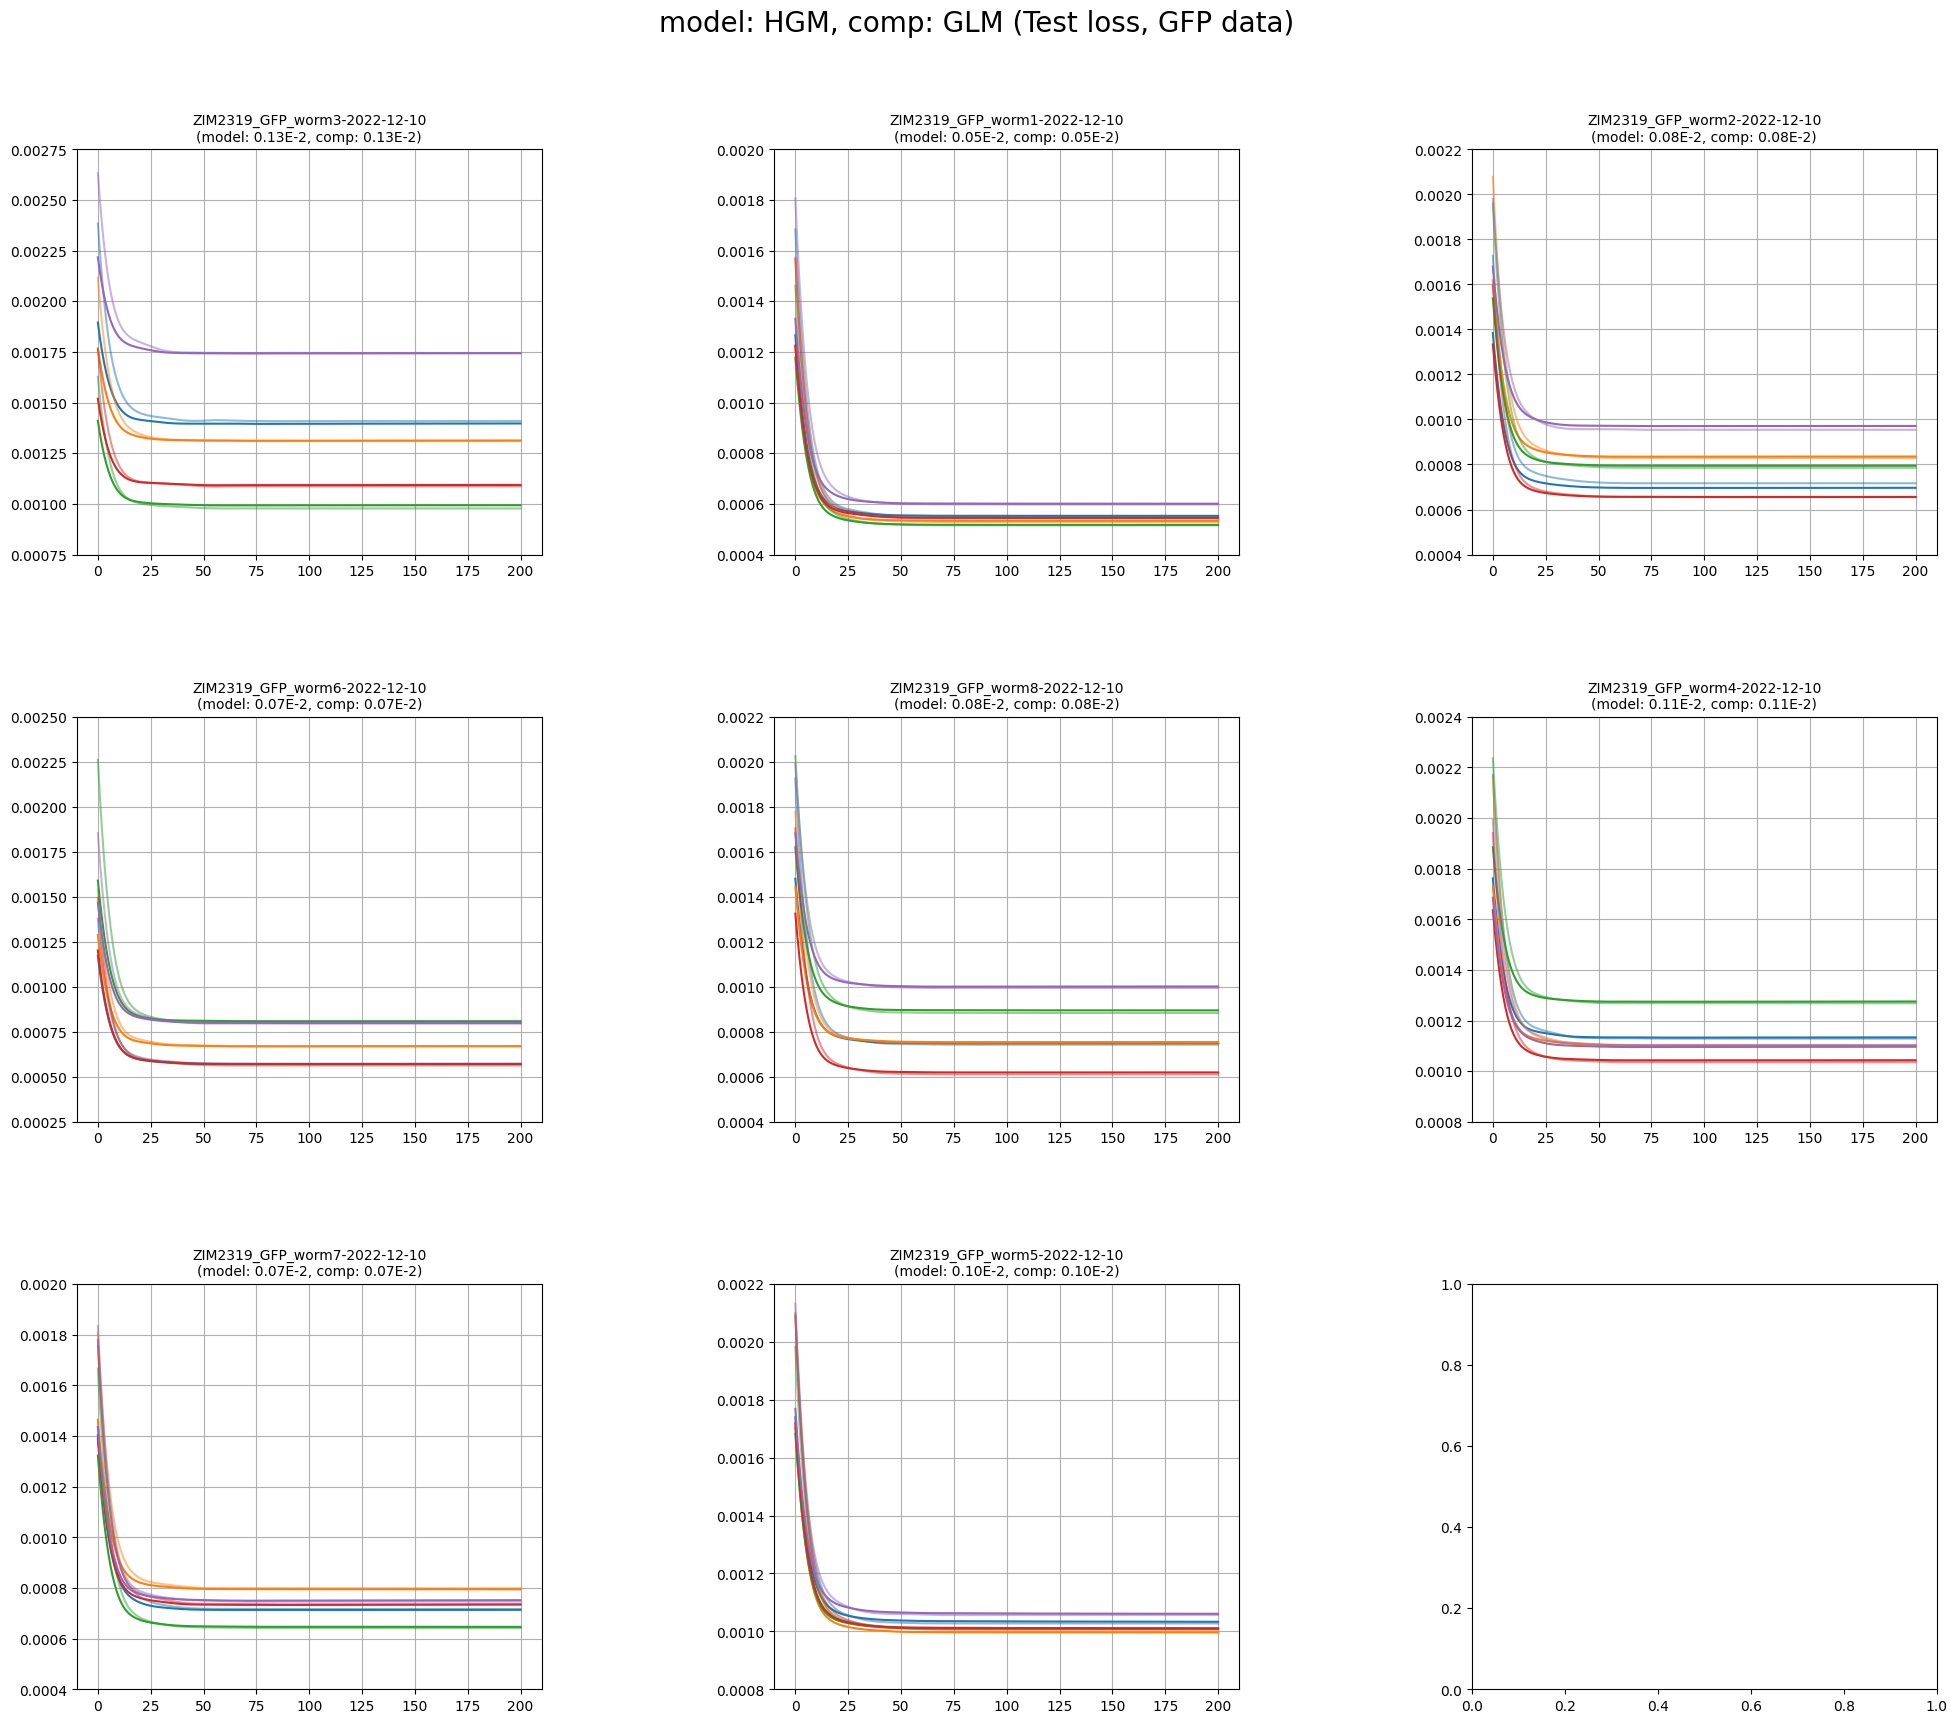

In [34]:
plot_utils.plot_losses(filenames_gfp, hgm_models_losses_gfp, glm_models_losses_gfp, 'model: HGM, comp: GLM (Test loss, GFP data)')

# assemble

In [35]:
neurons_labels = [traces[i].columns for i in range(len(filenames))]

unique_labels = sorted(list(set([l for label in neurons_labels for l in label])))
unique_labels_filtered = [label for label in unique_labels if label != '' and label[-1] != '_']

neuron_scores = dict()
glm_models_avg_scores = [np.mean(scores, axis=0) for scores in glm_models_scores]
hgm_models_avg_scores = [np.mean(scores, axis=0) for scores in hgm_models_scores]
for label_list, score_glm_list, score_hgm_list in zip(neurons_labels, glm_models_avg_scores, hgm_models_avg_scores):
	for i in range(len(label_list)):
		label = label_list[i]
		if label != '' and label[-1] != '_':
			score_glm_new, score_hgm_new = np.array(score_glm_list[i]), np.array(score_hgm_list[i])
			if len(score_hgm_new.shape) == 0:
				score_glm_new = score_glm_new.reshape(1, 1)
				score_hgm_new = score_hgm_new.reshape(1, 1)
			if label not in neuron_scores.keys():
				neuron_scores[label] = (score_glm_new, score_hgm_new)
			else:
				score_glm_prev, score_hgm_prev = neuron_scores[label]
				neuron_scores[label] = (np.vstack([score_glm_prev, score_glm_new]), np.vstack([score_hgm_prev, score_hgm_new]))

In [36]:
neurons_labels_gfp = [traces_gfp[i].columns for i in range(len(filenames_gfp))]

unique_labels_gfp = sorted(list(set([l for label in neurons_labels_gfp for l in label])))
unique_labels_filtered_gfp = [label for label in unique_labels_gfp if label != '' and label[-1] != '_']

neuron_scores_gfp = dict()
glm_models_avg_scores_gfp = [np.mean(scores, axis=0) for scores in glm_models_scores_gfp]
hgm_models_avg_scores_gfp = [np.mean(scores, axis=0) for scores in hgm_models_scores_gfp]
for label_list, score_glm_list, score_hgm_list in zip(neurons_labels_gfp, glm_models_avg_scores_gfp, hgm_models_avg_scores_gfp):  # TODO: unique_labels_filtered_gfp instead of neuron_labels_gfp???
	for i in range(len(label_list)):
		label = label_list[i]
		if label != '' and label[-1] != '_':
			score_glm_new, score_hgm_new = np.array(score_glm_list[i]), np.array(score_hgm_list[i])
			if len(score_hgm_new.shape) == 0:
				score_glm_new = score_glm_new.reshape(1, 1)
				score_hgm_new = score_hgm_new.reshape(1, 1)
			if label not in neuron_scores_gfp.keys():
				neuron_scores_gfp[label] = (score_glm_new, score_hgm_new)
			else:
				score_glm_prev, score_hgm_prev = neuron_scores_gfp[label]
				neuron_scores_gfp[label] = (np.vstack([score_glm_prev, score_glm_new]), np.vstack([score_hgm_prev, score_hgm_new]))

# Plot

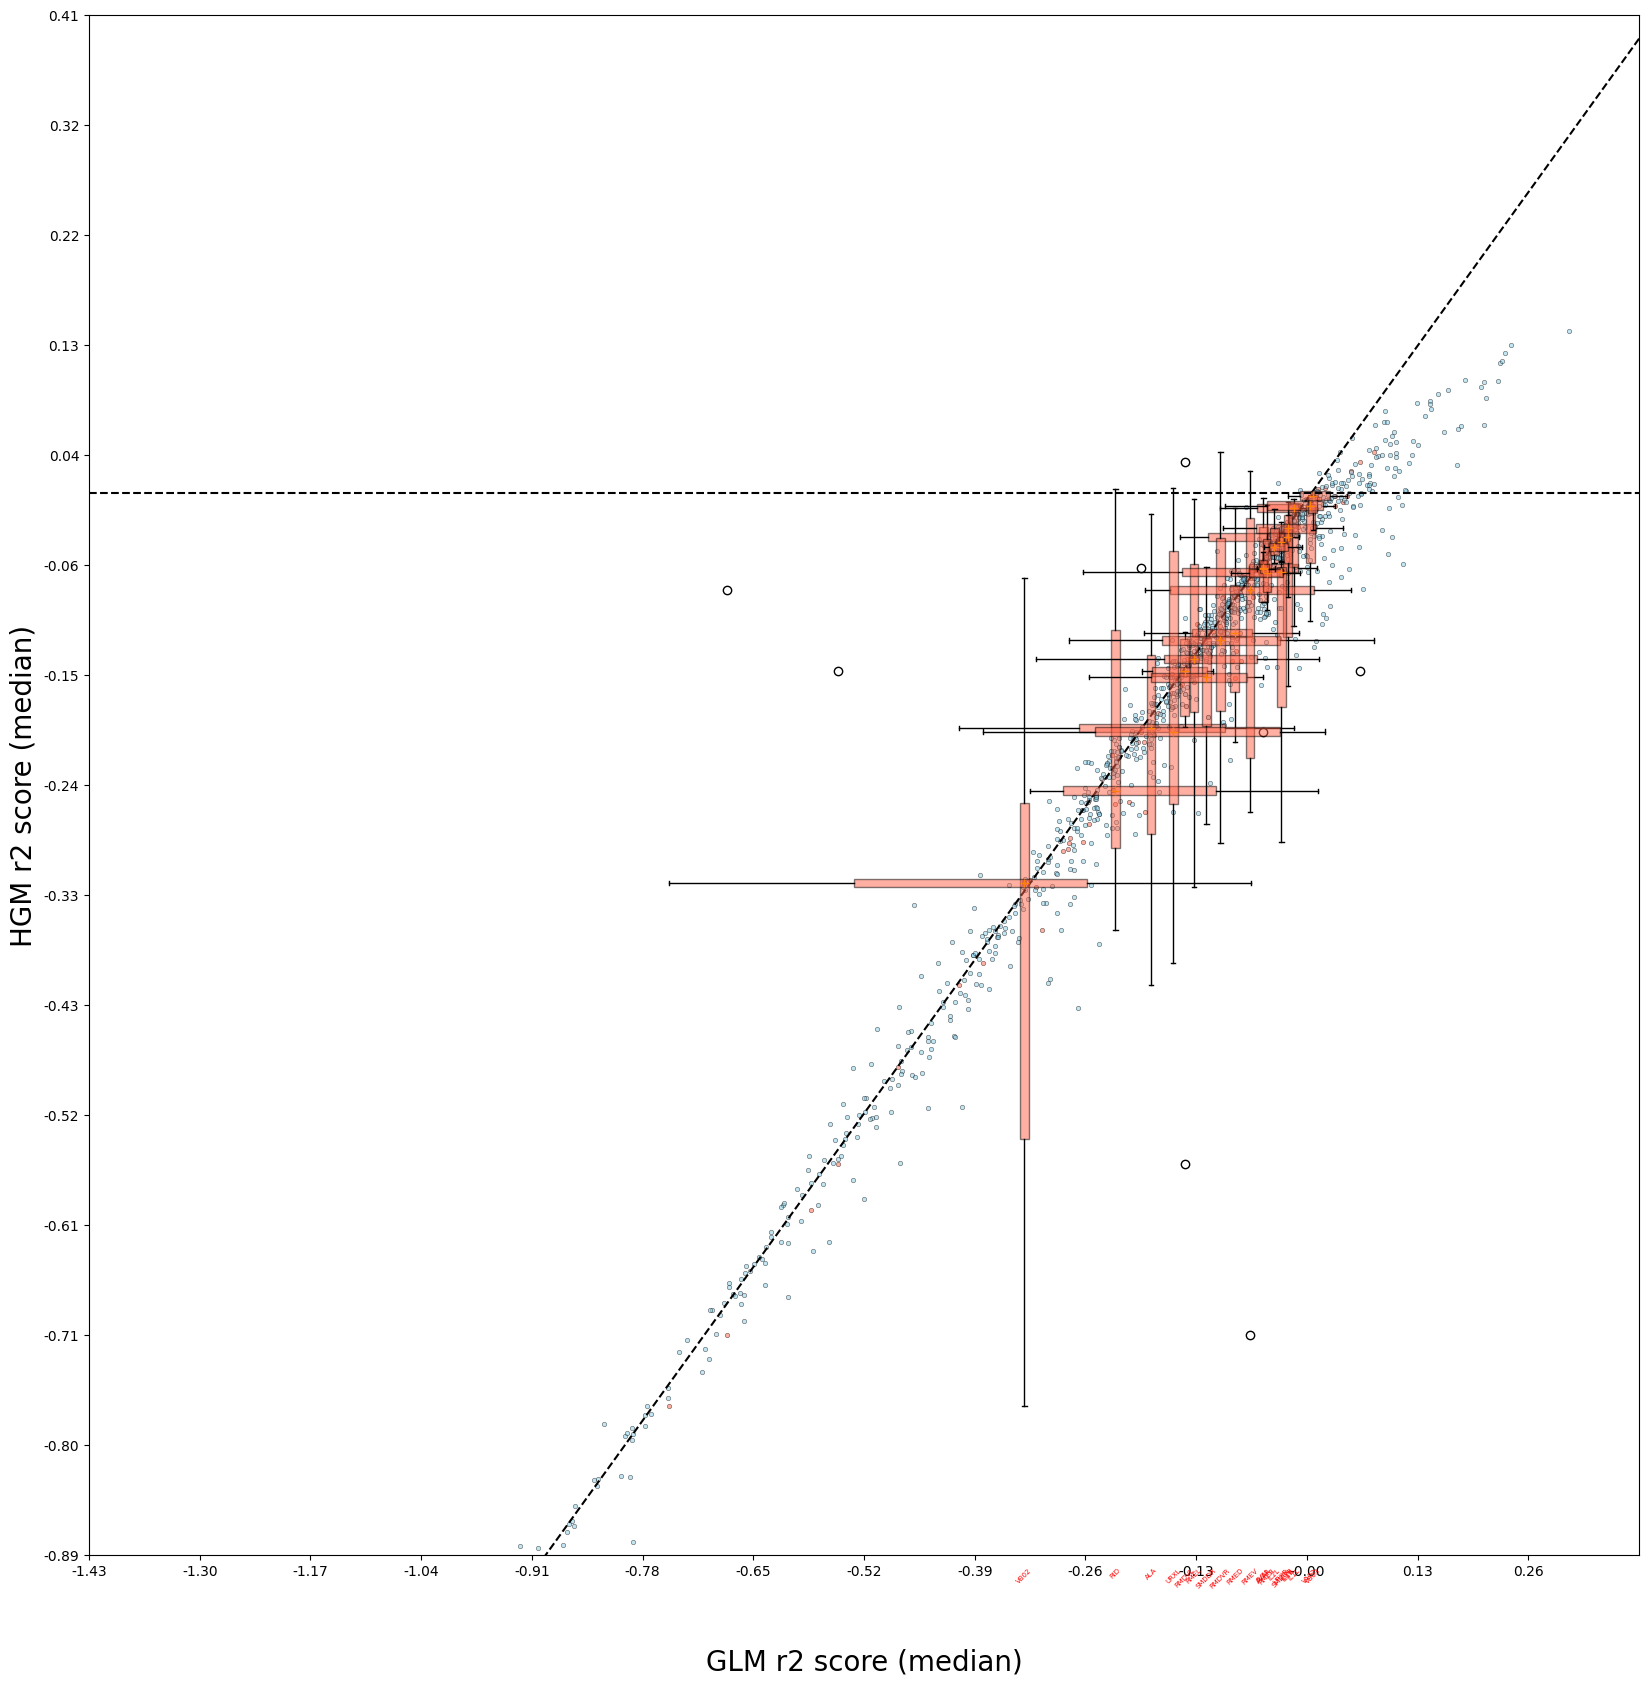

In [37]:
plot_utils.plot_performance_plot(neuron_scores, neuron_scores_gfp, None, save=True)

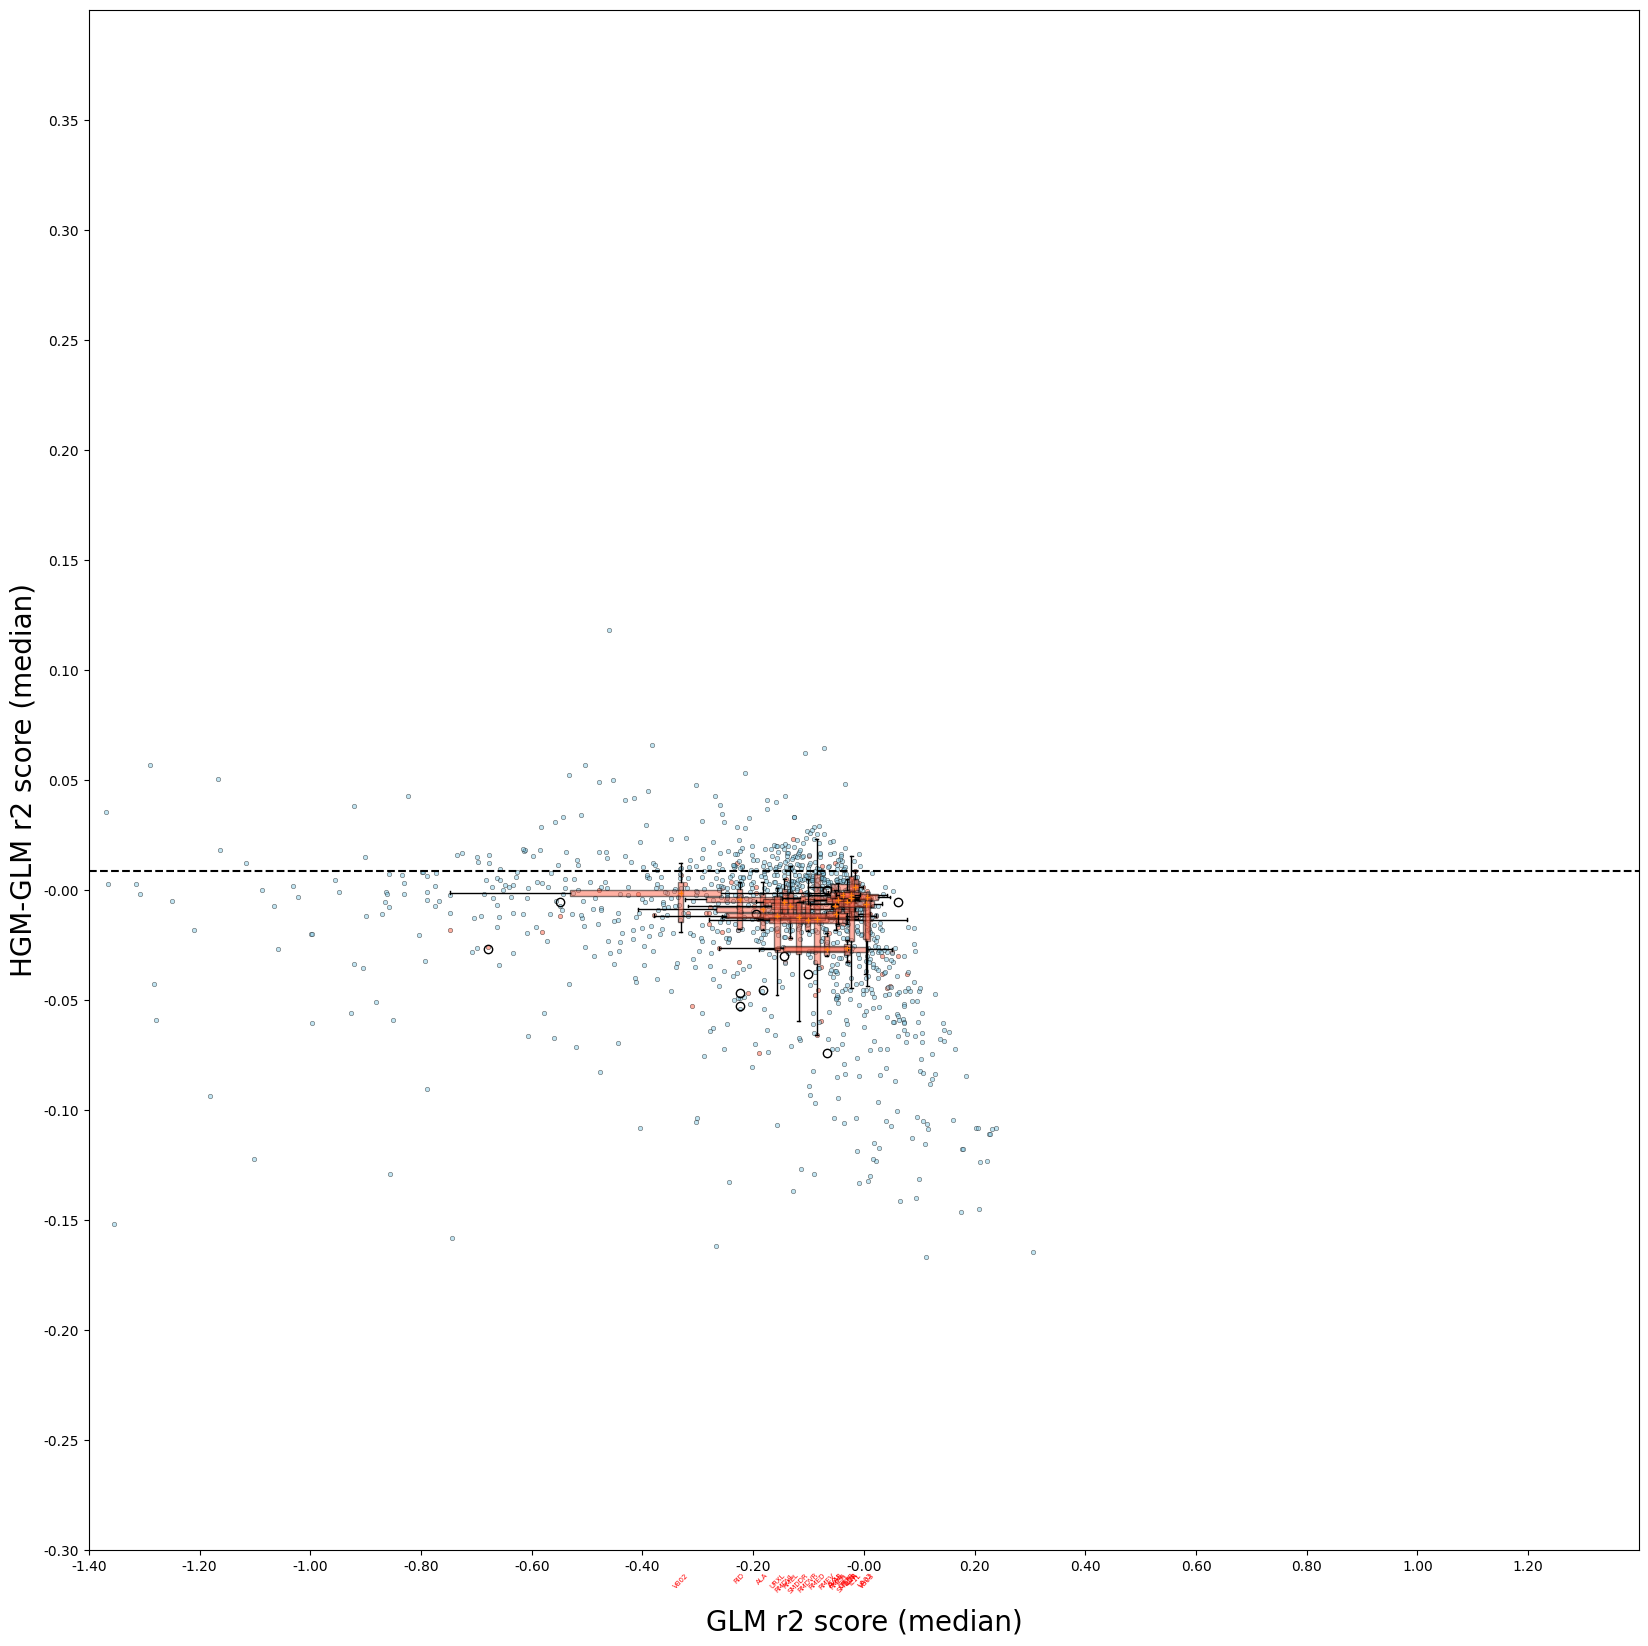

In [38]:
plot_utils.plot_improvement_plot(neuron_scores, neuron_scores_gfp, (-1, 1, -0.2, 0.3), save=False)

In [39]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)
importlib.reload(artificializer)
importlib.reload(glm)
importlib.reload(hgm)

<module 'models.hgm_sep' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/Work/Workspaces/UNIVIE/VisualStudioCode/Python/MSc_Thesis/data_exploration/worm-2025-fieseler/models/hgm_sep.py'>

# Final models

In [40]:
# todo